![Play Store Analysis Banner](images/banner.png)

# What Makes a Play Store App Successful? Installs, Reviews, Ratings, Price, Size and Updates

**A CRISP-DM analysis using PySpark, Pandas, and Tableau Public**

## Overview

**BLUF (Bottom Line Up Front):** This project starts from one headline question, *is there a relationship between an app's download volume (installs) and the number of reviews it receives?*, and extends it into a set of **eight research questions (RQ1 to RQ8)** about what goes with app success: ratings by category, free vs. paid, size, price, update recency, audience, genre crowding, and a combined model. Each question has a stated hypothesis, a justified statistical method, an effect size with uncertainty, and an **auto-generated answer** computed from the data (no number in this notebook is typed in from memory).

The final cell of the Data Analysis section assembles all answers into a **research scorecard**, and the Conclusion refers back to it.

**The story in five steps**
1. Raw store data is messy (text installs like `"10,000+"`, text prices, mixed-unit sizes, duplicate apps, a malformed row).
2. After cleaning, installs and reviews are extremely right-skewed, so raw averages mislead and log or rank methods are used.
3. The install-review relationship is measured several ways (RQ1), then seven further questions are answered with the right test for each.
4. A combined regression (RQ8) checks which relationships survive when everything is considered together.
5. Results are summarized for developers, product managers, and investors and explored in a Tableau dashboard.

> **Environment note.** This notebook deliberately **does not need `pyarrow`**. Python UDFs and Arrow-based Spark-to-Pandas transfer are avoided (native Spark expressions and a `collect()`-based converter are used instead), which removes the `ModuleNotFoundError: No module named 'pyarrow'` failure on PySpark 4.x.

## Business Understanding

**Why this matters.** Developers, product teams, and investors all try to read success from public signals. Reviews are the most visible one, but their meaning depends on how they relate to installs, ratings, price, and other app traits. This project tests those relationships carefully, and says clearly where the evidence is weak.

**Stakeholders**

| Stakeholder | Decision they face | How this analysis helps |
|---|---|---|
| App developers | Which category, price point, and size should we target? How many reviews should we expect? | Benchmarks for review rate, rating, size, and update cadence |
| Product managers | Should we charge for the app, prompt for reviews, or keep updating? | Evidence on price, size, and recency versus installs and ratings |
| Investors / publishers | Can public counts screen for traction? Which genres are crowded? | Reliability of reviews as a popularity proxy; genre concentration |
| Marketing teams | Which categories turn installs into reviews and high ratings? | Category comparisons with uncertainty |

**Primary question**
> **RQ1. Is there a relationship between download volume (Installs) and the number of Reviews an app receives, and how strong is it?**

**Research questions, hypotheses, and methods**

| ID | Research question | Hypothesis (H1) | Method | Effect size reported |
|---|---|---|---|---|
| RQ1 | Do apps with more installs get more reviews? How strong, and is it a category artifact? | Reviews rise with installs (positive monotonic relationship) | Spearman, Kendall, log-log regression, bootstrap CI, within-category checks, residuals | rho, slope, R² |
| RQ2 | Which categories have the best ratings? | Median ratings differ across categories | Kruskal-Wallis, bootstrap CI of medians | epsilon², CI overlap |
| RQ3 | Do paid apps earn higher ratings than free apps? | Paid apps are rated higher | Mann-Whitney U, bootstrap CI, category-adjusted comparison | Cliff's delta, median difference |
| RQ4 | How does app size relate to installs and ratings? | Larger apps have fewer installs | Spearman, size bands, category-adjusted correlation | rho |
| RQ5 | How does price relate to installs? | Higher price goes with fewer installs | Mann-Whitney, Spearman among paid apps, price bands | Cliff's delta, rho |
| RQ6 | How do installs and ratings vary with update recency? | Recently updated apps have more installs and higher ratings | Spearman, recency bands, share of fresh apps by install tier | rho |
| RQ7 | Which content-rating groups and genres dominate or are crowded? | Market is concentrated in a few genres and in "Everyone" | Shares, HHI concentration, apps vs. installs per app | HHI, saturation index |
| RQ8 | Which relationships survive when all factors are considered together? | Installs remain the dominant correlate of reviews after controls | OLS with category effects, standardized coefficients | R², delta R² |

**Interpretation note.** "Download volume" is the `Installs` column and "number of reviews" is the `Reviews` column. If a different pair was intended, change the two column names in the RQ1 cells.

**Scope note.** All findings are associations in a single scraped snapshot, not causal effects.

## Data Understanding

**Source.** The file `./data/google_play_store_dataset.csv` has the structure of the public Kaggle *Google Play Store Apps* dataset (one row per app listing, scraped from the Play Store). *Confirm the exact source and access date and cite them here.* The file is small (about 4 MB, roughly 10,800 rows), so a local Spark session is more than enough.

**Columns**

| Column | Meaning | Stored as | Keep? |
|---|---|---|---|
| `App` | App name | text | Yes (identifier) |
| `Category` | Store category | text | Yes |
| `Rating` | Average user rating | number | Yes |
| `Reviews` | Number of user reviews | text | **Yes (key variable)** |
| `Size` | App size, e.g. `19M`, `201k`, `Varies with device` | text | Yes, converted to MB |
| `Installs` | Install bucket, e.g. `10,000+` | text | **Yes (key variable)**, converted to a number |
| `Type` | Free or Paid | text | Yes |
| `Price` | Price, e.g. `$2.99` | text | Yes, converted to a number |
| `Content Rating` | Target audience | text | Yes |
| `Genres` | Genre(s), `;`-separated | text | Yes, primary genre extracted |
| `Last Updated` | Date of last update | text | Yes, parsed to a date |
| `Current Ver`, `Android Ver` | Version strings | text | **No**: messy free text with little analytic value here |

**Data issues expected** (all *verified by code* in the EDA section, with counts):
- Numeric information stored as text (`Installs`, `Price`, `Reviews`, `Size`).
- Missing values, most notably in `Rating`.
- Duplicate app listings.
- A malformed row whose values are shifted into the wrong columns.
- `Size` equal to `Varies with device` for many apps.
- Dates stored as text.

**Important property of `Installs`.** It is a *bucket* (a lower bound such as 10,000+), not an exact count. Many apps share a value, which creates ties in rank correlation and limits precision.

**Important property of `Rating`.** Apps with few reviews often have no rating. Rating analyses therefore describe apps that attracted enough reviews to be rated, which is a selection effect that is tested explicitly in RQ2.

In [1]:
# Run once if packages are missing, then restart the kernel.
# NOTE: pyarrow is NOT required by this notebook.
# %pip install pyspark pandas numpy matplotlib seaborn scipy

In [2]:
# Imports and project configuration
import os
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# Make Spark's Python worker use THIS interpreter (avoids version/module mismatches in venv/pipx installs)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---- Project configuration (single place to change paths) ----
RAW_PATH = "./data/google_play_store_dataset.csv"
CLEAN_PATH = "./data/google_play_store_cleaned.csv"
IMG_DIR = "./images"
RANDOM_SEED = 42
MIN_N = 30                      # minimum group size for category/genre comparisons
GREEN, BLUE, RED, GREY = "#01875f", "#4285f4", "#d93025", "#9aa0a6"   # consistent palette (match Tableau)
ANSWERS = {}                    # research-question answers are collected here for the final scorecard
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(os.path.dirname(CLEAN_PATH) or ".", exist_ok=True)

print("Python:", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python: 3.12.3 | pandas 2.3.2 | numpy 2.3.2


### Phase 1: Environment Configuration and Data Loading

**Spark configuration choices (and why)**
- `master("local[*]")`: use all local CPU cores; no cluster is needed for ~10k rows.
- `spark.sql.shuffle.partitions = 8`: the default of 200 creates hundreds of tiny tasks for a dataset this small.
- `spark.driver.memory = 2g`: ample for this data.
- `spark.sql.ansi.enabled = false`: invalid casts (for example `"Free"` to a number) return `null` instead of raising an error, which the cleaning logic relies on.
- `spark.sql.execution.arrow.pyspark.enabled = false` and `spark.sql.execution.pythonUDF.arrow.enabled = false`: **keeps Spark from using Apache Arrow**, so `pyarrow` is not needed.
- `spark.sql.session.timeZone = UTC`: avoids time zone surprises.

**Loading choices**
- `inferSchema = False`: every column is read as **text** on purpose. One malformed row would otherwise corrupt type inference for whole columns. Types are applied explicitly during cleaning.
- `nullValue = "NaN"`: the file stores missing ratings as the literal text `NaN`.
- `multiLine` plus `quote`/`escape` set to `"`: app names contain commas and quotes.

In [3]:
def get_spark(app_name: str = "PlayStoreAnalysis") -> SparkSession:
    """Create (or reuse) a local SparkSession tuned for a small dataset, with Arrow disabled."""
    return (
        SparkSession.builder.appName(app_name)
        .master("local[*]")
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.driver.memory", "2g")
        .config("spark.sql.ansi.enabled", "false")
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.sql.execution.arrow.pyspark.enabled", "false")      # no pyarrow needed
        .config("spark.sql.execution.pythonUDF.arrow.enabled", "false")    # no pyarrow needed
        .config("spark.ui.showConsoleProgress", "false")
        .getOrCreate()
    )

spark = get_spark()
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/15 00:06:34 WARN Utils: Your hostname, DESKTOP-7641MJU, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/15 00:06:34 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 00:06:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/15 00:06:37 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark version: 4.3.0


In [4]:
# ---- Pure-Python helpers (no Spark needed, so they are easy to unit-test) ----

EXPECTED_COLUMNS = [
    "app", "category", "rating", "reviews", "size", "installs", "type",
    "price", "content_rating", "genres", "last_updated", "current_ver", "android_ver",
]

# One regex shared by the Python parser and the native Spark expression, so they cannot drift apart
SIZE_PATTERN = r"^\s*([0-9]+(?:\.[0-9]+)?)\s*([kKmMgG])\s*$"
VALID_INSTALLS = r"^[0-9,]+\+?$"   # e.g. '10,000+' or '0'

def to_snake(name: str) -> str:
    """'Content Rating' -> 'content_rating' (consistent, Spark-friendly column names)."""
    return re.sub(r"\W+", "_", name.strip()).strip("_").lower()

def parse_size_mb(size):
    """Python reference: '19M' -> 19.0, '201k' -> 0.196, '1.2G' -> 1228.8. Anything else -> None."""
    if size is None:
        return None
    match = re.fullmatch(SIZE_PATTERN, str(size))
    if not match:
        return None  # e.g. 'Varies with device'
    value, unit = float(match.group(1)), match.group(2).lower()
    return value / 1024 if unit == "k" else value if unit == "m" else value * 1024

def size_mb_expr(col_name: str = "size"):
    """Native Spark column expression equivalent to parse_size_mb. Runs inside the JVM: no Python worker, no pyarrow."""
    num = F.regexp_extract(F.col(col_name), SIZE_PATTERN, 1)
    unit = F.lower(F.regexp_extract(F.col(col_name), SIZE_PATTERN, 2))
    value = num.cast("double")
    return (
        F.when(unit == "k", value / 1024)
         .when(unit == "m", value)
         .when(unit == "g", value * 1024)
         .otherwise(F.lit(None).cast("double"))
    )

def fmt_installs(n: int) -> str:
    """1000 -> '1K+', 5000000 -> '5M+', 500 -> '500+' (readable install bucket labels)."""
    n = int(n)
    if n >= 1_000_000_000: return f"{n // 1_000_000_000}B+"
    if n >= 1_000_000:     return f"{n // 1_000_000}M+"
    if n >= 1_000:         return f"{n // 1_000}K+"
    return f"{n}+"

def strength_label(r: float) -> str:
    """Plain-English label for the size of a correlation coefficient."""
    a = abs(r)
    if a < 0.2: return "negligible"
    if a < 0.4: return "weak"
    if a < 0.6: return "moderate"
    if a < 0.8: return "strong"
    return "very strong"

def to_pandas_safe(sdf) -> pd.DataFrame:
    """Spark -> Pandas WITHOUT Arrow/pyarrow: collect rows, build the frame, restore numeric dtypes."""
    out = pd.DataFrame([r.asDict() for r in sdf.collect()], columns=sdf.columns)
    numeric_types = ("double", "float", "bigint", "int", "smallint", "tinyint")
    for field in sdf.schema.fields:
        if field.dataType.simpleString() in numeric_types or field.dataType.simpleString().startswith("decimal"):
            out[field.name] = pd.to_numeric(out[field.name], errors="coerce")
    return out

def fmt_p(p: float) -> str:
    """Format a p-value; very small values are shown as '< 1e-300'."""
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"

# ---- Statistical helpers used by the research questions ----
def cliffs_delta(a, b) -> float:
    """Cliff's delta = P(a > b) - P(a < b), from the Mann-Whitney U statistic. Range -1..1, ties handled."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return float(2 * u / (len(a) * len(b)) - 1)

def delta_label(d: float) -> str:
    """Romano et al. thresholds for the magnitude of Cliff's delta."""
    a = abs(d)
    if a < 0.147: return "negligible"
    if a < 0.33:  return "small"
    if a < 0.474: return "medium"
    return "large"

def epsilon_squared(groups) -> tuple:
    """Kruskal-Wallis H, p-value and epsilon-squared effect size (share of rank variance explained by group)."""
    h, p = stats.kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    return float(h), float(p), float(max(0.0, (h - k + 1) / (n - k)))

def eps2_label(e: float) -> str:
    if e < 0.01: return "negligible"
    if e < 0.08: return "small"
    if e < 0.26: return "medium"
    return "large"

def bootstrap_median_ci(values, n_boot: int = 1000, seed: int = RANDOM_SEED):
    """95% bootstrap CI for a median."""
    rng = np.random.default_rng(seed)
    v = np.asarray(values, float)
    meds = np.median(rng.choice(v, size=(n_boot, len(v)), replace=True), axis=1)
    return np.percentile(meds, [2.5, 97.5])

def bootstrap_median_diff_ci(a, b, n_boot: int = 2000, seed: int = RANDOM_SEED):
    """95% bootstrap CI for median(a) - median(b)."""
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    ma = np.median(rng.choice(a, size=(n_boot, len(a)), replace=True), axis=1)
    mb = np.median(rng.choice(b, size=(n_boot, len(b)), replace=True), axis=1)
    return np.percentile(ma - mb, [2.5, 97.5])

def hhi(counts) -> float:
    """Herfindahl-Hirschman index on shares (0..1). 1/n = perfectly even, 1 = one group holds everything."""
    c = np.asarray(counts, float)
    s = c / c.sum()
    return float((s ** 2).sum())

def ols_fit(df: pd.DataFrame, y: str, numeric: list, categorical: str = None) -> dict:
    """OLS with standardized numeric predictors and optional category dummies (numpy only, no extra packages)."""
    cols = [y] + numeric + ([categorical] if categorical else [])
    d = df[cols].dropna()
    yv = d[y].to_numpy(float)
    yz = (yv - yv.mean()) / yv.std(ddof=0)
    blocks = [np.ones((len(d), 1))]
    if numeric:
        X = d[numeric].astype(float)
        blocks.append(((X - X.mean()) / X.std(ddof=0)).to_numpy())
    if categorical:
        blocks.append(pd.get_dummies(d[categorical], drop_first=True, dtype=float).to_numpy())
    A = np.hstack(blocks)
    beta, *_ = np.linalg.lstsq(A, yz, rcond=None)
    resid = yz - A @ beta
    r2 = 1 - float(resid @ resid) / float(yz @ yz)
    coefs = pd.Series(beta[1:1 + len(numeric)], index=numeric, dtype=float)
    return {"r2": r2, "coefs": coefs, "n": len(d)}

# ---- Unit tests (evidence of testing) ----
assert to_snake("Content Rating") == "content_rating"
assert to_snake("  Last Updated ") == "last_updated"
assert parse_size_mb("19M") == 19.0
assert abs(parse_size_mb("201k") - 201 / 1024) < 1e-9
assert parse_size_mb("1G") == 1024.0
assert parse_size_mb("1.5M") == 1.5
assert parse_size_mb("Varies with device") is None
assert parse_size_mb(None) is None
assert fmt_installs(500) == "500+" and fmt_installs(10_000) == "10K+" and fmt_installs(5_000_000) == "5M+"
assert strength_label(0.9) == "very strong" and strength_label(-0.1) == "negligible"
assert cliffs_delta([1, 2, 3], [0]) == 1.0 and cliffs_delta([0], [1, 2, 3]) == -1.0
assert abs(cliffs_delta([1, 2, 3], [1, 2, 3])) < 1e-12
assert delta_label(0.1) == "negligible" and delta_label(-0.5) == "large"
assert abs(hhi([1, 1, 1, 1]) - 0.25) < 1e-12 and hhi([5]) == 1.0
_t = pd.DataFrame({"y": [1.0, 2, 3, 4, 5], "x": [2.0, 4, 6, 8, 10]})
assert abs(ols_fit(_t, "y", ["x"])["r2"] - 1.0) < 1e-9
print("All helper unit tests passed.")

All helper unit tests passed.


In [5]:
# ---- Native Spark size parser: verify it against the Python reference, and (optionally) a UDF ----
SIZE_SAMPLES = ["19M", "201k", "1.5G", "Varies with device", "8.5M", "1,000+", "", None]

def native_vs_reference(samples) -> bool:
    """Check the native Spark expression against parse_size_mb on sample strings (JVM only, no Python worker)."""
    test = spark.createDataFrame([(s,) for s in samples], "size string")
    got = to_pandas_safe(test.select("size", size_mb_expr("size").alias("native")))
    for s, native in zip(samples, got["native"]):
        expected = parse_size_mb(s)
        same = (expected is None and pd.isna(native)) or (expected is not None and abs(expected - native) < 1e-9)
        assert same, f"Mismatch for {s!r}: native={native}, reference={expected}"
    return True

def optional_udf_crosscheck(samples) -> str:
    """
    Demonstrate a Python UDF as an OPTIONAL cross-check. A Python UDF needs a working Python worker (and, on
    some PySpark 4.x builds, pyarrow), so failure here is reported and skipped; the pipeline never depends on it.
    """
    try:
        try:
            udf = F.udf(parse_size_mb, DoubleType(), useArrow=False)   # PySpark >= 3.5
        except TypeError:
            udf = F.udf(parse_size_mb, DoubleType())
        test = spark.createDataFrame([(s,) for s in samples], "size string")
        out = to_pandas_safe(test.select(size_mb_expr("size").alias("native"), udf("size").alias("udf")))
        ok = np.allclose(out["native"].fillna(-1), out["udf"].fillna(-1))
        return "UDF cross-check passed" if ok else "UDF cross-check DISAGREES with native expression"
    except Exception as exc:                                         # noqa: BLE001
        return f"UDF cross-check skipped (Python worker unavailable: {type(exc).__name__}). Pipeline unaffected."

print("Native size expression matches Python reference:", native_vs_reference(SIZE_SAMPLES))
print(optional_udf_crosscheck(SIZE_SAMPLES))

Native size expression matches Python reference: True
UDF cross-check passed


In [6]:
def load_raw(path: str):
    """Read the raw CSV with PySpark; every column is read as text on purpose."""
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Dataset not found at '{path}'. Put the CSV there or change RAW_PATH."
        )
    df = (
        spark.read.option("header", True)
        .option("inferSchema", False)       # types are applied explicitly during cleaning
        .option("multiLine", True)
        .option("quote", '"').option("escape", '"')
        .option("nullValue", "NaN")         # the file stores missing ratings as the text NaN
        .csv(path)
    )
    return df.toDF(*[to_snake(c) for c in df.columns])

try:
    raw_sdf = load_raw(RAW_PATH)
    raw_sdf.cache()                         # reused many times below; avoid re-reading the file
    n_rows = raw_sdf.count()                # action: materializes the cache
except Exception as exc:
    raise RuntimeError(f"Could not load the dataset: {exc}") from exc

# ---- Basic load verification ----
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw_sdf.columns]
assert n_rows > 0, "Loaded DataFrame is empty"
assert not missing_cols, f"Missing expected columns: {missing_cols}"

print(f"Rows: {n_rows:,} | Columns: {len(raw_sdf.columns)}")
raw_sdf.printSchema()
raw_sdf.show(5, truncate=40)

Rows: 10,841 | Columns: 13
root
 |-- app: string (nullable = true)
 |-- category: string (nullable = true)
 |-- rating: string (nullable = true)
 |-- reviews: string (nullable = true)
 |-- size: string (nullable = true)
 |-- installs: string (nullable = true)
 |-- type: string (nullable = true)
 |-- price: string (nullable = true)
 |-- content_rating: string (nullable = true)
 |-- genres: string (nullable = true)
 |-- last_updated: string (nullable = true)
 |-- current_ver: string (nullable = true)
 |-- android_ver: string (nullable = true)

+----------------------------------------+--------------+------+-------+----+-----------+----+-----+--------------+-------------------------+----------------+------------------+------------+
|                                     app|      category|rating|reviews|size|   installs|type|price|content_rating|                   genres|    last_updated|       current_ver| android_ver|
+----------------------------------------+--------------+------+------

### Phase 3: Exploratory Data Analysis (PySpark)

**Spark vs. Pandas in this notebook.** Spark is used for loading, profiling, and the bulk cleaning transformations. Spark evaluates **lazily**: `filter`, `withColumn`, and `select` only build a plan, and work happens when an *action* such as `count()`, `show()`, or `collect()` runs. Because the raw DataFrame is reused many times, it is `cache()`d after loading. The cleaned data (about 10k rows, well under 10 MB) is moved to Pandas with a `collect()`-based converter (no Arrow) for date parsing, feature engineering, statistics, and plotting.

In [7]:
# 1. Statistical analysis: descriptive statistics on the numeric-looking columns
# (casting invalid text to double gives null because ANSI mode is off)
numeric_view = raw_sdf.select(
    F.col("rating").cast("double").alias("rating"),
    F.col("reviews").cast("double").alias("reviews"),
)
print("Descriptive statistics (raw values cast to numbers; invalid text becomes null):")
numeric_view.summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show()

print("Sample of key text-formatted columns that must be converted:")
raw_sdf.select("size", "installs", "price", "last_updated").show(8, truncate=30)

Descriptive statistics (raw values cast to numbers; invalid text becomes null):
+-------+------------------+------------------+
|summary|            rating|           reviews|
+-------+------------------+------------------+
|  count|              9367|             10840|
|   mean| 4.193338315362448|444152.89603321033|
| stddev|0.5374313031477593|2927760.6038856646|
|    min|               1.0|               0.0|
|    25%|               4.0|              38.0|
|    50%|               4.3|            2093.0|
|    75%|               4.5|           54520.0|
|    max|              19.0|       7.8158306E7|
+-------+------------------+------------------+

Sample of key text-formatted columns that must be converted:
+----+-----------+-----+----------------+
|size|   installs|price|    last_updated|
+----+-----------+-----+----------------+
| 19M|    10,000+|    0| January 7, 2018|
| 14M|   500,000+|    0|January 15, 2018|
|8.7M| 5,000,000+|    0|  August 1, 2018|
| 25M|50,000,000+|    0|    Ju

In [8]:
# 2a. Completeness: null counts per column
null_counts = to_pandas_safe(raw_sdf.select(
    [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw_sdf.columns]
)).T.rename(columns={0: "null_count"})
null_counts["null_pct"] = null_counts["null_count"] / n_rows * 100
display(null_counts.sort_values("null_count", ascending=False))

# 2b. Duplicates: full-row duplicates and duplicate app names
full_dupes = n_rows - raw_sdf.dropDuplicates().count()
distinct_apps = raw_sdf.select("app").distinct().count()
print(f"Fully duplicated rows:      {full_dupes:,}")
print(f"Distinct app names:         {distinct_apps:,}  ->  repeated app rows: {n_rows - distinct_apps:,}")

# 2c. Unique value counts per column
distinct_counts = to_pandas_safe(raw_sdf.agg(
    *[F.countDistinct(c).alias(c) for c in raw_sdf.columns]
)).T.rename(columns={0: "distinct_values"})
display(distinct_counts)

,null_count,null_pct
rating,1474,13.597
current_ver,8,0.074
android_ver,3,0.028
content_rating,1,0.009
type,1,0.009
size,0,0.000
reviews,0,0.000
category,0,0.000
app,0,0.000
price,0,0.000


Fully duplicated rows:      483
Distinct app names:         9,660  ->  repeated app rows: 1,181


,distinct_values
app,9660
category,34
rating,40
reviews,6002
size,462
installs,22
type,3
price,93
content_rating,6
genres,120


In [9]:
# 2d. Distributions of the main categorical columns
for col in ["type", "content_rating", "installs"]:
    print(f"\n--- {col}: value counts ---")
    raw_sdf.groupBy(col).count().orderBy(F.desc("count")).show(25, truncate=40)

print("\n--- category: top 15 by number of rows ---")
raw_sdf.groupBy("category").count().orderBy(F.desc("count")).show(15, truncate=40)


--- type: value counts ---
+----+-----+
|type|count|
+----+-----+
|Free|10039|
|Paid|  800|
|NULL|    1|
|   0|    1|
+----+-----+


--- content_rating: value counts ---
+---------------+-----+
| content_rating|count|
+---------------+-----+
|       Everyone| 8714|
|           Teen| 1208|
|     Mature 17+|  499|
|   Everyone 10+|  414|
|Adults only 18+|    3|
|        Unrated|    2|
|           NULL|    1|
+---------------+-----+


--- installs: value counts ---
+--------------+-----+
|      installs|count|
+--------------+-----+
|    1,000,000+| 1579|
|   10,000,000+| 1252|
|      100,000+| 1169|
|       10,000+| 1054|
|        1,000+|  907|
|    5,000,000+|  752|
|          100+|  719|
|      500,000+|  539|
|       50,000+|  479|
|        5,000+|  477|
|  100,000,000+|  409|
|           10+|  386|
|          500+|  330|
|   50,000,000+|  289|
|           50+|  205|
|            5+|   82|
|  500,000,000+|   72|
|            1+|   67|
|1,000,000,000+|   58|
|            0+|   14|
|  

In [10]:
# 3. Anomaly detection: rows that do not look like valid app records
is_bad_installs = ~F.coalesce(F.col("installs").rlike(VALID_INSTALLS), F.lit(False))
is_bad_rating = F.col("rating").cast("double") > 5

bad_rows = raw_sdf.filter(is_bad_installs | is_bad_rating)
n_bad = bad_rows.count()
print(f"Rows whose Installs value is not a valid install bucket, or Rating > 5: {n_bad}")
bad_rows.show(truncate=30)

n_rating_oor = raw_sdf.filter(F.col("rating").cast("double").isNotNull() &
                              ~F.col("rating").cast("double").between(1, 5)).count()
n_varies = raw_sdf.filter(F.col("size") == "Varies with device").count()
n_dollar = raw_sdf.filter(F.col("price").contains("$")).count()
print("Ratings outside 1-5 (excluding nulls):", n_rating_oor)
print("'Varies with device' sizes:", n_varies)
print("Rows with a '$' price:", n_dollar)

Rows whose Installs value is not a valid install bucket, or Rating > 5: 1
+------------------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+
|                           app|category|rating|reviews|  size|installs|type|   price|content_rating|           genres|last_updated|current_ver|android_ver|
+------------------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+
|Life Made WI-Fi Touchscreen...|     1.9|    19|   3.0M|1,000+|    Free|   0|Everyone|          NULL|February 11, 2018|      1.0.19| 4.0 and up|       NULL|
+------------------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+

Ratings outside 1-5 (excluding nulls): 1
'Varies with device' sizes: 1695
Rows with a '$' price: 800


In [11]:
# 4. Problem identification: a data-driven, prioritized issue log (counts come from the data)
n_null_rating = raw_sdf.filter(F.col("rating").isNull()).count()
n_null_type = raw_sdf.filter(F.col("type").isNull()).count()
n_multi_genre = raw_sdf.filter(F.col("genres").contains(";")).count()

issues = pd.DataFrame([
    ("High",   "Malformed row(s): shifted columns / invalid Installs or Rating", n_bad,
     "Remove rows whose Installs is not a valid bucket"),
    ("High",   "Duplicate app listings (same App repeated)", n_rows - distinct_apps,
     "Keep one row per app: highest Reviews, then highest Installs (window function)"),
    ("High",   "Installs stored as text ('10,000+')", n_rows, "Strip ',' and '+', cast to long"),
    ("High",   "Reviews stored as text", n_rows, "Cast to long"),
    ("High",   "Price stored as text ('$2.99')", n_dollar, "Strip '$', cast to double"),
    ("Medium", "Size in mixed units / 'Varies with device'", n_rows,
     "Native Spark expression converts k/M/G to MB; 'Varies' becomes null with a flag"),
    ("Medium", "Missing Rating", n_null_rating,
     "Keep as null (not imputed); test whether missingness is related to popularity (RQ2)"),
    ("Medium", "Missing Type", n_null_type, "Derive from Price (0 = Free, >0 = Paid)"),
    ("Medium", "Last Updated stored as text", n_rows, "Parse to a date in Pandas"),
    ("Low",    "Current Ver / Android Ver: messy free text", n_rows, "Drop (not relevant to the research questions)"),
    ("Low",    "Genres contain multiple values separated by ';'", n_multi_genre, "Extract the primary genre"),
], columns=["priority", "issue", "rows_affected", "planned_fix"])
display(issues)

,priority,issue,rows_affected,planned_fix
0,High,Malformed row(s): shifted columns / invalid In...,1,Remove rows whose Installs is not a valid bucket
1,High,Duplicate app listings (same App repeated),1181,"Keep one row per app: highest Reviews, then hi..."
2,High,"Installs stored as text ('10,000+')",10841,"Strip ',' and '+', cast to long"
3,High,Reviews stored as text,10841,Cast to long
4,High,Price stored as text ('$2.99'),800,"Strip '$', cast to double"
5,Medium,Size in mixed units / 'Varies with device',10841,Native Spark expression converts k/M/G to MB; ...
6,Medium,Missing Rating,1474,Keep as null (not imputed); test whether missi...
7,Medium,Missing Type,1,"Derive from Price (0 = Free, >0 = Paid)"
8,Medium,Last Updated stored as text,10841,Parse to a date in Pandas
9,Low,Current Ver / Android Ver: messy free text,10841,Drop (not relevant to the research questions)


**Assumptions and decisions (documented before cleaning)**
1. A row is malformed if `Installs` is not a valid install bucket; such rows cannot be repaired reliably and are removed.
2. When an app appears more than once, the row with the most reviews is kept (the most recent and complete snapshot of that app's reviews).
3. Missing `Rating` values are **not imputed**. Imputing would distort rating analysis; they are excluded from rating-based statistics, and the effect of that exclusion is tested in RQ2.
4. `Installs` is the *lower bound* of the bucket (`10,000+` becomes 10,000).
5. For log transforms, `log10(x + 1)` is used so apps with 0 reviews can be included; a robustness check excludes them.
6. All tests use rank-based or bootstrap methods because installs, reviews, and prices are heavily skewed. Significance level is 0.05, but **effect sizes are reported first**, because with about 10k apps nearly any difference is "significant".

## Data Preparation

### Phase 4: Cleaning (PySpark first, then Pandas)

**Pipeline**
1. **PySpark** (bulk, scalable): remove malformed rows, cast types, convert `Size` with a **native Spark expression** (no Python UDF), remove duplicates with a **window function** (`row_number`), add a within-category install percentile with a second window function (`percent_rank`), then `cache()` the result.
2. **Pandas** (small, fiddly): parse dates, extract primary genre, build log features, bands, and ordered install buckets.
3. **Validate** with automated assertions, then **export** to CSV for Tableau.

**Why no UDF?** A Python UDF forces Spark to start a separate Python worker, which on PySpark 4.x imports `pyarrow`. Native expressions run inside the JVM, are faster (no Python serialization), and have no extra dependency. The earlier notebook failed exactly here. A UDF is still demonstrated above as an *optional* cross-check that is skipped safely if unavailable.

In [12]:
def clean_with_spark(df):
    """
    Bulk-clean the raw Spark DataFrame. Returns (clean_df, audit) where audit records
    row counts after each step so every removal is documented.
    """
    audit = {"rows_in": df.count()}

    # 1. Remove malformed rows (Installs must look like '10,000+')
    step = df.filter(F.coalesce(F.col("installs").rlike(VALID_INSTALLS), F.lit(False)))
    audit["after_malformed_removal"] = step.count()

    # 2. Type conversions and standardization (all native Spark expressions)
    step = (
        step
        .withColumn("rating", F.col("rating").cast("double"))
        .withColumn("reviews", F.col("reviews").cast("long"))
        .withColumn("installs", F.regexp_replace("installs", r"[,+]", "").cast("long"))
        .withColumn("price", F.regexp_replace("price", r"\$", "").cast("double"))
        .withColumn("size_mb", size_mb_expr("size"))
        # Type: keep valid values, otherwise derive from price
        .withColumn(
            "type",
            F.when(F.col("type").isin("Free", "Paid"), F.col("type"))
             .when(F.col("price") > 0, F.lit("Paid"))
             .otherwise(F.lit("Free")),
        )
    )

    # 3. Required fields must be present
    step = step.dropna(subset=["app", "category", "installs", "reviews", "price"])
    audit["after_required_fields"] = step.count()

    # 4. Ratings must be within 1-5 when present (nulls are allowed and kept)
    step = step.filter(F.col("rating").isNull() | F.col("rating").between(1.0, 5.0))
    audit["after_rating_range"] = step.count()

    # 5. De-duplicate apps with a WINDOW function: keep the row with most reviews per app
    w_dedup = Window.partitionBy("app").orderBy(
        F.col("reviews").desc_nulls_last(), F.col("installs").desc_nulls_last()
    )
    step = step.withColumn("rn", F.row_number().over(w_dedup)).filter(F.col("rn") == 1).drop("rn")
    audit["after_deduplication"] = step.count()

    # 6. Second window function: each app's install percentile within its category
    w_cat = Window.partitionBy("category").orderBy("installs")
    step = step.withColumn("installs_pct_rank_in_category", F.percent_rank().over(w_cat))

    return step, audit

In [13]:
try:
    clean_sdf, audit = clean_with_spark(raw_sdf)
    clean_sdf.cache()                 # reused for stats, outliers, and the Pandas hand-off
    n_clean = clean_sdf.count()       # action: runs the whole plan once and fills the cache
except Exception as exc:
    raise RuntimeError(f"Spark cleaning step failed: {exc}") from exc

audit_df = pd.DataFrame({"step": list(audit.keys()), "rows": list(audit.values())})
audit_df["rows_removed_in_step"] = (audit_df["rows"].shift(1) - audit_df["rows"]).fillna(0).astype(int)
display(audit_df)
print(f"Rows kept: {n_clean:,} of {n_rows:,} ({n_clean / n_rows:.1%})")

clean_sdf.printSchema()
clean_sdf.select("app", "category", "rating", "reviews", "size_mb", "installs", "type", "price").show(5, truncate=30)

,step,rows,rows_removed_in_step
0,rows_in,10841,0
1,after_malformed_removal,10840,1
2,after_required_fields,10840,0
3,after_rating_range,10840,0
4,after_deduplication,9659,1181


Rows kept: 9,659 of 10,841 (89.1%)
root
 |-- app: string (nullable = true)
 |-- category: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- reviews: long (nullable = true)
 |-- size: string (nullable = true)
 |-- installs: long (nullable = true)
 |-- type: string (nullable = true)
 |-- price: double (nullable = true)
 |-- content_rating: string (nullable = true)
 |-- genres: string (nullable = true)
 |-- last_updated: string (nullable = true)
 |-- current_ver: string (nullable = true)
 |-- android_ver: string (nullable = true)
 |-- size_mb: double (nullable = true)
 |-- installs_pct_rank_in_category: double (nullable = false)

+------------------------------+-------------------+------+-------+-------+--------+----+-----+
|                           app|           category|rating|reviews|size_mb|installs|type|price|
+------------------------------+-------------------+------+-------+-------+--------+----+-----+
| Pistolet CZ-70 CZ-50 expliqué|BOOKS_AND_REFERENCE|  NULL|

In [14]:
# Spark-side outlier summary with IQR fences (approxQuantile is a distributed, approximate quantile)
for col in ["reviews", "installs"]:
    q1, q3 = clean_sdf.approxQuantile(col, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    n_out = clean_sdf.filter(F.col(col) > upper).count()
    print(f"{col:9s} Q1={q1:>14,.0f}  Q3={q3:>14,.0f}  upper fence={upper:>16,.0f}  "
          f"apps above fence: {n_out:,} ({n_out / n_clean:.1%})")

print("\nBoth variables are extremely right-skewed: a few blockbuster apps dominate. "
      "This motivates log scales and rank-based (Spearman) correlation below.")

# Pearson correlation computed natively in Spark on the RAW (unlogged) values: a naive baseline only
print("\nSpark Pearson correlation, raw installs vs raw reviews:",
      round(clean_sdf.stat.corr("installs", "reviews"), 4))

reviews   Q1=            25  Q3=        27,104  upper fence=          67,722  apps above fence: 1,724 (17.8%)
installs  Q1=         1,000  Q3=     1,000,000  upper fence=       2,498,500  apps above fence: 1,981 (20.5%)

Both variables are extremely right-skewed: a few blockbuster apps dominate. This motivates log scales and rank-based (Spearman) correlation below.

Spark Pearson correlation, raw installs vs raw reviews: 0.6251


In [15]:
# Move the cleaned (small) dataset from Spark to Pandas. No Arrow / pyarrow involved.
pdf = to_pandas_safe(clean_sdf)
print("Spark -> Pandas:", pdf.shape)

Spark -> Pandas: (9659, 15)


In [16]:
def engineer_features(pdf: pd.DataFrame) -> pd.DataFrame:
    """Pandas stage: dates, genre, log features, readable and ordered buckets, and analysis bands."""
    df = pdf.copy()

    # Dates
    df["last_updated"] = pd.to_datetime(df["last_updated"], format="%B %d, %Y", errors="coerce")
    snapshot_date = df["last_updated"].max()                      # dataset 'now'
    df["days_since_update"] = (snapshot_date - df["last_updated"]).dt.days

    # Text tidy-up
    df["category"] = df["category"].str.replace("_", " ").str.title().str.replace(" And ", " & ")
    df["primary_genre"] = df["genres"].str.split(";").str[0].str.strip()

    # Flags
    df["is_paid"] = df["type"].eq("Paid")
    df["size_missing"] = df["size_mb"].isna()
    df["has_rating"] = df["rating"].notna()

    # Log features (log10(x + 1) keeps zeros usable) and review rate
    df["log10_installs"] = np.log10(df["installs"] + 1)
    df["log10_reviews"] = np.log10(df["reviews"] + 1)
    df["log10_price1"] = np.log10(df["price"] + 1)
    df["log10_size_mb"] = np.log10(df["size_mb"])
    df["reviews_per_1k_installs"] = np.where(df["installs"] > 0, df["reviews"] / df["installs"] * 1000, np.nan)

    # Ordered install buckets (for charts and Tableau sorting)
    labels_in_order = [fmt_installs(v) for v in sorted(df["installs"].unique())]
    df["installs_bucket"] = pd.Categorical(
        df["installs"].map(fmt_installs), categories=labels_in_order, ordered=True
    )
    df["installs_bucket_rank"] = df["installs"].rank(method="dense").astype(int)

    # Analysis bands (ordered, so charts and Tableau sort correctly)
    size_labels = ["<5 MB", "5-15 MB", "15-30 MB", "30-60 MB", "60+ MB"]
    df["size_band"] = pd.cut(df["size_mb"], bins=[0, 5, 15, 30, 60, np.inf], labels=size_labels, right=False)
    df["size_band"] = df["size_band"].cat.add_categories("Varies with device").fillna("Varies with device")

    price_labels = ["Free", "$0.01-0.99", "$1-2.99", "$3-9.99", "$10+"]
    df["price_band"] = pd.Categorical(
        np.select([df["price"] == 0, df["price"] < 1, df["price"] < 3, df["price"] < 10], price_labels[:4],
                  default=price_labels[4]),
        categories=price_labels, ordered=True)

    recency_labels = ["0-30 days", "31-90 days", "91-365 days", "1-2 years", "2+ years"]
    df["recency_band"] = pd.cut(df["days_since_update"], bins=[-1, 30, 90, 365, 730, np.inf], labels=recency_labels)

    df["install_tier"] = pd.Categorical(
        np.select([df["installs"] < 10_000, df["installs"] < 1_000_000], ["<10K", "10K-1M"], default="1M+"),
        categories=["<10K", "10K-1M", "1M+"], ordered=True)

    # Drop columns that are not relevant to the analysis
    return df.drop(columns=["size", "current_ver", "android_ver"], errors="ignore")

clean_df = engineer_features(pdf)
print("Shape after feature engineering:", clean_df.shape)
display(clean_df.head())
display(clean_df.dtypes.astype(str).to_frame("dtype").T)

Shape after feature engineering: (9659, 28)


,app,category,rating,reviews,installs,type,price,content_rating,genres,last_updated,size_mb,installs_pct_rank_in_category,days_since_update,primary_genre,is_paid,size_missing,has_rating,log10_installs,log10_reviews,log10_price1,log10_size_mb,reviews_per_1k_installs,installs_bucket,installs_bucket_rank,size_band,price_band,recency_band,install_tier
0,Pistolet CZ-70 CZ-50 expliqué,Books & Reference,NaN,0,1,Paid,5.990,Everyone,Books & Reference,2016-11-01,17.000,0.000,645,Books & Reference,True,False,False,0.301,0.000,0.844,1.230,0.000,1+,2,15-30 MB,$3-9.99,1-2 years,<10K
1,BibleRead En Cy Zh Yue,Books & Reference,NaN,0,5,Free,0.000,Everyone,Books & Reference,2018-05-17,12.000,0.005,83,Books & Reference,False,False,False,0.778,0.000,0.000,1.079,0.000,5+,3,5-15 MB,Free,31-90 days,<10K
2,CZ-38 (vz 38) pistol explained,Books & Reference,NaN,0,5,Paid,5.990,Everyone,Books & Reference,2017-08-10,13.000,0.005,363,Books & Reference,True,False,False,0.778,0.000,0.844,1.114,0.000,5+,3,5-15 MB,$3-9.99,91-365 days,<10K
3,CZ-Help,Books & Reference,5.000,2,5,Free,0.000,Everyone,Books & Reference,2018-07-13,1.400,0.005,26,Books & Reference,False,False,True,0.778,0.477,0.000,0.146,400.000,5+,3,<5 MB,Free,0-30 days,<10K
4,EW PDF,Books & Reference,NaN,0,5,Free,0.000,Everyone,Books & Reference,2018-02-14,8.700,0.005,175,Books & Reference,False,False,False,0.778,0.000,0.000,0.940,0.000,5+,3,5-15 MB,Free,91-365 days,<10K


,app,category,rating,reviews,installs,type,price,content_rating,genres,last_updated,size_mb,installs_pct_rank_in_category,days_since_update,primary_genre,is_paid,size_missing,has_rating,log10_installs,log10_reviews,log10_price1,log10_size_mb,reviews_per_1k_installs,installs_bucket,installs_bucket_rank,size_band,price_band,recency_band,install_tier
dtype,object,object,float64,int64,int64,object,float64,object,object,datetime64[ns],float64,float64,int64,object,bool,bool,bool,float64,float64,float64,float64,float64,category,int64,category,category,category,category


In [17]:
def validate_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    """
    Automated validation of the cleaned data. Raises AssertionError listing every failure
    and returns a table of passed checks (evidence of testing).
    """
    checks = {
        "no duplicate apps":                       not df["app"].duplicated().any(),
        "no null app/category/installs/reviews/price": df[["app", "category", "installs", "reviews", "price"]].notna().all().all(),
        "ratings within 1-5 (nulls allowed)":      df["rating"].dropna().between(1, 5).all(),
        "installs >= 0":                           (df["installs"] >= 0).all(),
        "reviews >= 0":                            (df["reviews"] >= 0).all(),
        "price >= 0":                              (df["price"] >= 0).all(),
        "type is Free or Paid":                    df["type"].isin(["Free", "Paid"]).all(),
        "paid apps have price > 0":                (df.loc[df["is_paid"], "price"] > 0).all(),
        "free apps have price == 0":               (df.loc[~df["is_paid"], "price"] == 0).all(),
        "size_mb positive when present":           (df["size_mb"].dropna() > 0).all(),
        "last_updated parsed (<1% null)":          df["last_updated"].isna().mean() < 0.01,
        "installs_bucket is ordered":              df["installs_bucket"].cat.ordered,
        "bands have no nulls (size, price, install tier)": df[["size_band", "price_band", "install_tier"]].notna().all().all(),
        "log columns finite":                      np.isfinite(df[["log10_installs", "log10_reviews", "log10_price1"]]).all().all(),
    }
    report = pd.DataFrame({"check": list(checks), "passed": [bool(v) for v in checks.values()]})
    failed = report.loc[~report["passed"], "check"].tolist()
    assert not failed, f"Validation failed: {failed}"
    return report

validation_report = validate_cleaned(clean_df)
display(validation_report)
print("All validation checks passed.")

,check,passed
0,no duplicate apps,True
1,no null app/category/installs/reviews/price,True
2,ratings within 1-5 (nulls allowed),True
3,installs >= 0,True
4,reviews >= 0,True
5,price >= 0,True
6,type is Free or Paid,True
7,paid apps have price > 0,True
8,free apps have price == 0,True
9,size_mb positive when present,True


All validation checks passed.


In [18]:
# Save cleaned data file for Tableau usage
def export_and_verify(df: pd.DataFrame, path: str) -> None:
    """Write the cleaned CSV, reload it, and verify rows, columns, and key values survived."""
    df.to_csv(path, index=False)
    reloaded = pd.read_csv(path)
    assert reloaded.shape == df.shape, f"Shape mismatch: {reloaded.shape} vs {df.shape}"
    assert list(reloaded.columns) == list(df.columns), "Column mismatch after export"
    assert reloaded["installs"].sum() == df["installs"].sum(), "Installs changed during export"
    assert reloaded["reviews"].sum() == df["reviews"].sum(), "Reviews changed during export"
    assert reloaded["app"].is_unique, "Duplicate apps appeared after export"
    print(f"Exported {len(reloaded):,} rows x {reloaded.shape[1]} columns to {path}")
    print(f"File size: {os.path.getsize(path) / 1024:,.0f} KB")

export_and_verify(clean_df, CLEAN_PATH)

Exported 9,659 rows x 28 columns to ./data/google_play_store_cleaned.csv
File size: 2,317 KB


**Limitations for downstream analysis**
- `Installs` is a bucket lower bound, so install analysis is approximate and has many ties.
- Apps with missing `Rating` are kept (rating is `null`) but are excluded from rating comparisons. They are mostly low-install apps (tested in RQ2), so rating results describe the *rated* part of the market.
- `size_mb` is missing for apps whose size "varies with device"; `size_missing` and the `Varies with device` size band flag them.
- `days_since_update` is measured against the newest update date in the dataset (a snapshot), not today's date.

## Data Analysis

### Phase 5: Exploration and Research Questions (notebook prototypes)

**Method plan.** RQ1 (the headline question) is tested several ways. RQ2 to RQ8 each follow the same pattern: *hypothesis, method, effect size with uncertainty, chart, auto-generated answer*. Every chart is saved to `./images/` and maps to a Tableau view in Phase 6.

---
## RQ1. Do apps with more installs get more reviews?

,count,mean,std,min,25%,50%,75%,90%,99%,max,skewness
installs,"9,659.000","7,798,170.248","53,769,728.818",0.000,"1,000.000","100,000.000","1,000,000.000","10,000,000.000","100,000,000.000","1,000,000,000.000",15.027
reviews,"9,659.000","216,804.110","1,831,430.213",0.000,25.000,969.000,"29,453.500","223,098.600","4,517,516.500","78,158,306.000",26.570


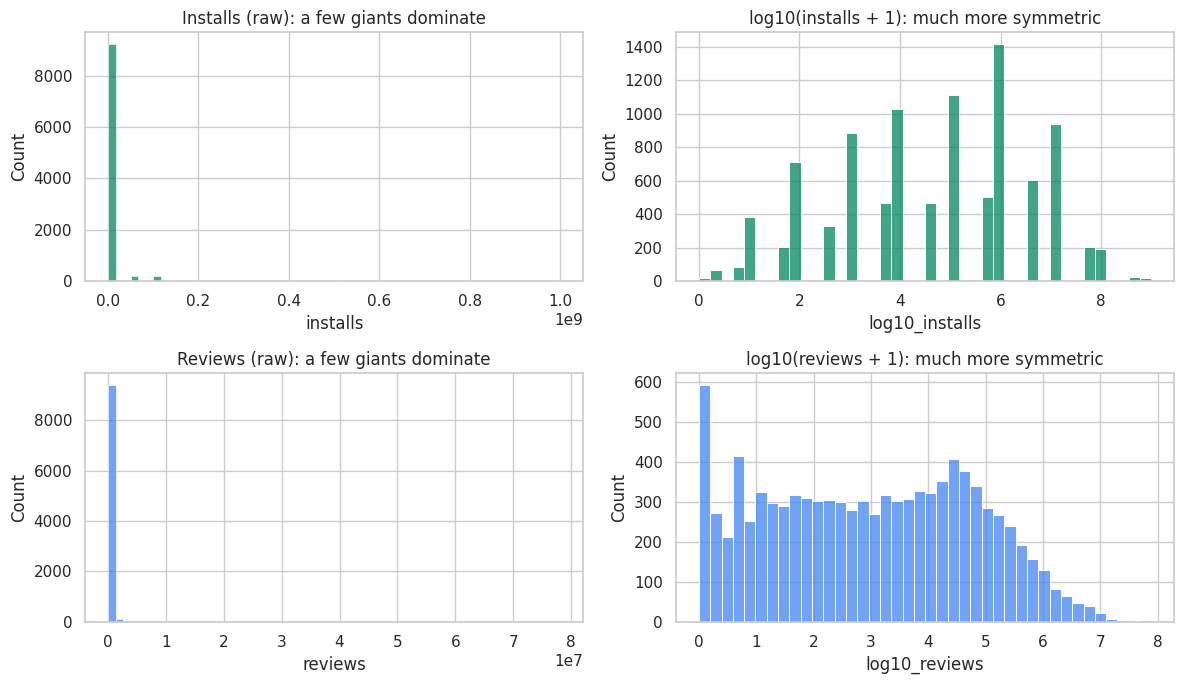

In [19]:
# RQ1 step 1. Describe the two key variables: heavy right skew
desc = clean_df[["installs", "reviews"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
desc["skewness"] = clean_df[["installs", "reviews"]].skew()
display(desc)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, color, row in [("installs", GREEN, 0), ("reviews", BLUE, 1)]:
    sns.histplot(clean_df[col], bins=60, ax=axes[row, 0], color=color)
    axes[row, 0].set_title(f"{col.title()} (raw): a few giants dominate")
    sns.histplot(clean_df[f"log10_{col}"], bins=40, ax=axes[row, 1], color=color)
    axes[row, 1].set_title(f"log10({col} + 1): much more symmetric")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/01_distributions.png", dpi=150)
plt.show()

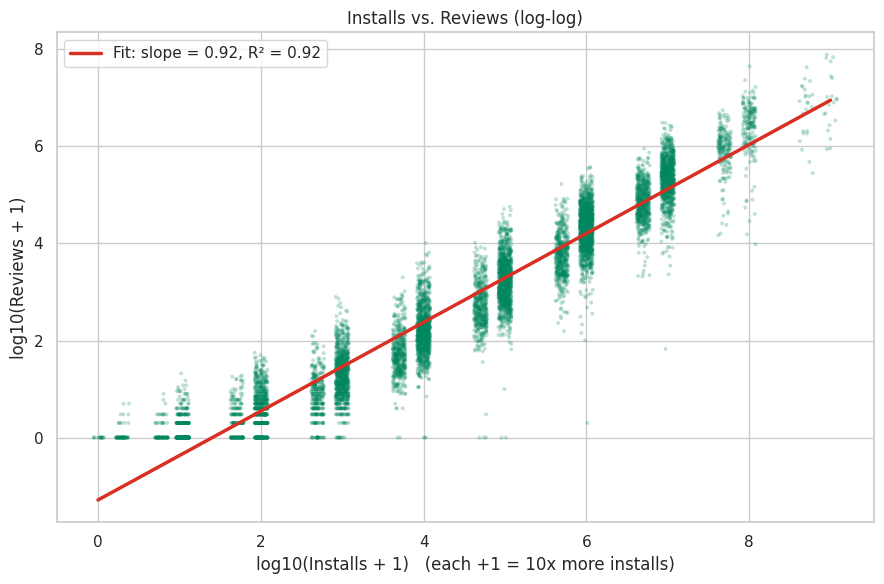

Log-log regression: slope = 0.916 (95% CI 0.910 to 0.921), R² = 0.919, n = 9,659
Interpretation: every 10x increase in installs goes with about a 8.2x increase in reviews.


In [20]:
# RQ1 step 2. The core relationship on log-log axes, with a fitted regression line
x, y = clean_df["log10_installs"], clean_df["log10_reviews"]
lr = stats.linregress(x, y)

rng = np.random.default_rng(RANDOM_SEED)
x_jitter = x + rng.uniform(-0.08, 0.08, size=len(x))   # jitter only for display: installs are buckets

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x_jitter, y, s=8, alpha=0.25, color=GREEN, edgecolor="none")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, lr.intercept + lr.slope * xs, color=RED, lw=2.5,
        label=f"Fit: slope = {lr.slope:.2f}, R² = {lr.rvalue**2:.2f}")
ax.set_xlabel("log10(Installs + 1)   (each +1 = 10x more installs)")
ax.set_ylabel("log10(Reviews + 1)")
ax.set_title("Installs vs. Reviews (log-log)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/02_installs_vs_reviews_loglog.png", dpi=150)
plt.show()

slope_ci = (lr.slope - 1.96 * lr.stderr, lr.slope + 1.96 * lr.stderr)
print(f"Log-log regression: slope = {lr.slope:.3f} (95% CI {slope_ci[0]:.3f} to {slope_ci[1]:.3f}), "
      f"R² = {lr.rvalue**2:.3f}, n = {len(x):,}")
print(f"Interpretation: every 10x increase in installs goes with about a {10 ** lr.slope:.1f}x increase in reviews.")

In [21]:
# RQ1 step 3. Correlation: several coefficients, because skew and ties affect them differently
def corr_table(df: pd.DataFrame) -> pd.DataFrame:
    """Install-review correlation using four methods, with p-values and sample size."""
    rows = []
    for name, fn, a, b in [
        ("Pearson (raw)",     stats.pearsonr,   df["installs"],        df["reviews"]),
        ("Pearson (log10)",   stats.pearsonr,   df["log10_installs"],  df["log10_reviews"]),
        ("Spearman (rank)",   stats.spearmanr,  df["installs"],        df["reviews"]),
        ("Kendall tau-b",     stats.kendalltau, df["installs"],        df["reviews"]),
    ]:
        res = fn(a, b)
        rows.append((name, float(res[0]), float(res[1]), len(df)))
    out = pd.DataFrame(rows, columns=["method", "coefficient", "p_value", "n"]).set_index("method")
    out["strength"] = out["coefficient"].map(strength_label)
    out["p_value"] = out["p_value"].map(fmt_p)
    return out

corr_df = corr_table(clean_df)
display(corr_df)

def bootstrap_spearman(a: pd.Series, b: pd.Series, n_boot: int = 1000, seed: int = RANDOM_SEED):
    """Bootstrap 95% CI for Spearman's rho."""
    rng = np.random.default_rng(seed)
    a, b, n = a.to_numpy(), b.to_numpy(), len(a)
    vals = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        vals[i] = stats.spearmanr(a[idx], b[idx])[0]
    return np.percentile(vals, [2.5, 97.5])

ci_lo, ci_hi = bootstrap_spearman(clean_df["installs"], clean_df["reviews"])
rho_s = float(corr_df.loc["Spearman (rank)", "coefficient"])
print(f"Spearman rho = {rho_s:.3f}, bootstrap 95% CI [{ci_lo:.3f}, {ci_hi:.3f}] (1,000 resamples)")

# Robustness: exclude apps with zero reviews
nz = clean_df[clean_df["reviews"] > 0]
rho_nz = stats.spearmanr(nz["installs"], nz["reviews"])[0]
print(f"Robustness check, apps with at least 1 review (n={len(nz):,}): Spearman rho = {rho_nz:.3f}")

,coefficient,p_value,n,strength
method,,,,
Pearson (raw),0.625,< 1e-300,9659,strong
Pearson (log10),0.959,< 1e-300,9659,very strong
Spearman (rank),0.968,< 1e-300,9659,very strong
Kendall tau-b,0.871,< 1e-300,9659,very strong


Spearman rho = 0.968, bootstrap 95% CI [0.966, 0.969] (1,000 resamples)
Robustness check, apps with at least 1 review (n=9,066): Spearman rho = 0.965


,installs_bucket,apps,installs_min,median_reviews,mean_reviews,median_reviews_per_1k_installs
0,0+,15,0,0.000,0.000,NaN
1,1+,67,1,0.000,0.299,0.000
2,5+,82,5,0.000,0.537,0.000
3,10+,385,10,0.000,1.088,0.000
4,50+,204,50,1.000,2.382,20.000
5,100+,709,100,3.000,5.440,30.000
6,500+,328,500,7.000,12.280,14.000
7,1K+,887,1000,19.000,37.753,19.000
8,5K+,468,5000,48.500,100.098,9.700
9,10K+,1030,10000,158.000,345.266,15.800


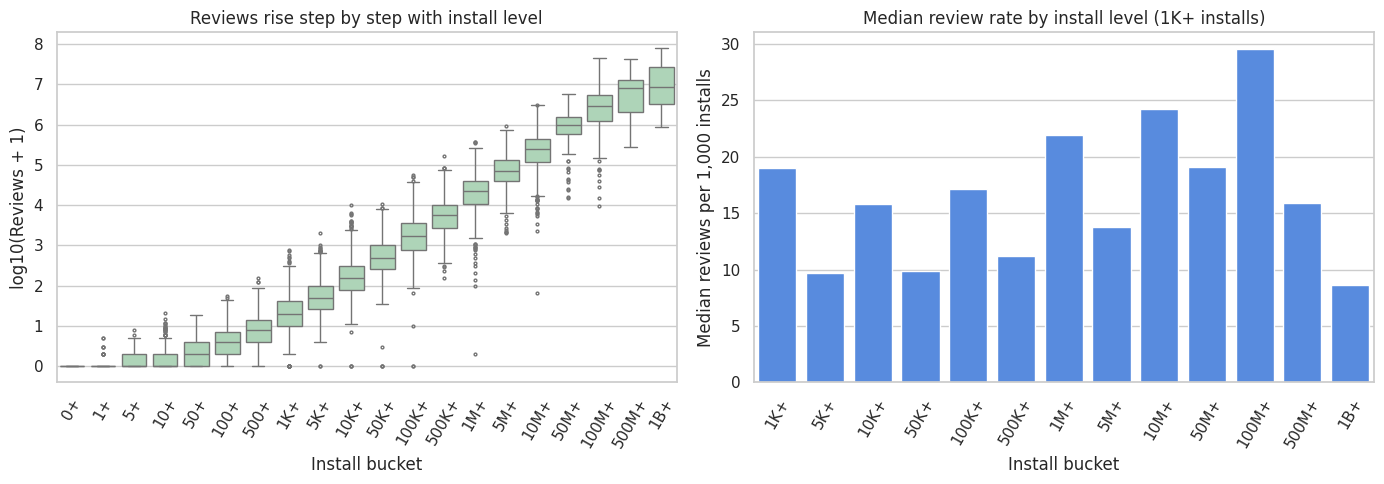

Median reviews strictly increase with install bucket: True


In [22]:
# RQ1 step 4. Is the REVIEW RATE stable across install levels? (reviews per 1,000 installs)
bucket_stats = (
    clean_df.groupby("installs_bucket", observed=True)
    .agg(apps=("app", "count"),
         installs_min=("installs", "min"),
         median_reviews=("reviews", "median"),
         mean_reviews=("reviews", "mean"),
         median_reviews_per_1k_installs=("reviews_per_1k_installs", "median"))
    .reset_index()
)
display(bucket_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=clean_df, x="installs_bucket", y="log10_reviews", ax=axes[0], color="#a8dab5", fliersize=2)
axes[0].set_title("Reviews rise step by step with install level")
axes[0].set_xlabel("Install bucket"); axes[0].set_ylabel("log10(Reviews + 1)")
axes[0].tick_params(axis="x", rotation=60)

# Tiny apps (a few installs, a few reviews) give extreme, noisy rates, so the rate chart starts at 1K+
rate_stats = bucket_stats[bucket_stats["installs_min"] >= 1_000]
sns.barplot(data=rate_stats, x="installs_bucket", y="median_reviews_per_1k_installs", ax=axes[1], color=BLUE,
            order=rate_stats["installs_bucket"].astype(str).tolist())
axes[1].set_title("Median review rate by install level (1K+ installs)")
axes[1].set_xlabel("Install bucket"); axes[1].set_ylabel("Median reviews per 1,000 installs")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/03_buckets.png", dpi=150)
plt.show()

monotonic = bool(bucket_stats["median_reviews"].is_monotonic_increasing)
print(f"Median reviews strictly increase with install bucket: {monotonic}")

,apps,spearman_rho
count,33.000,33.000
min,53.000,0.871
50%,219.000,0.961
max,"1,874.000",0.976


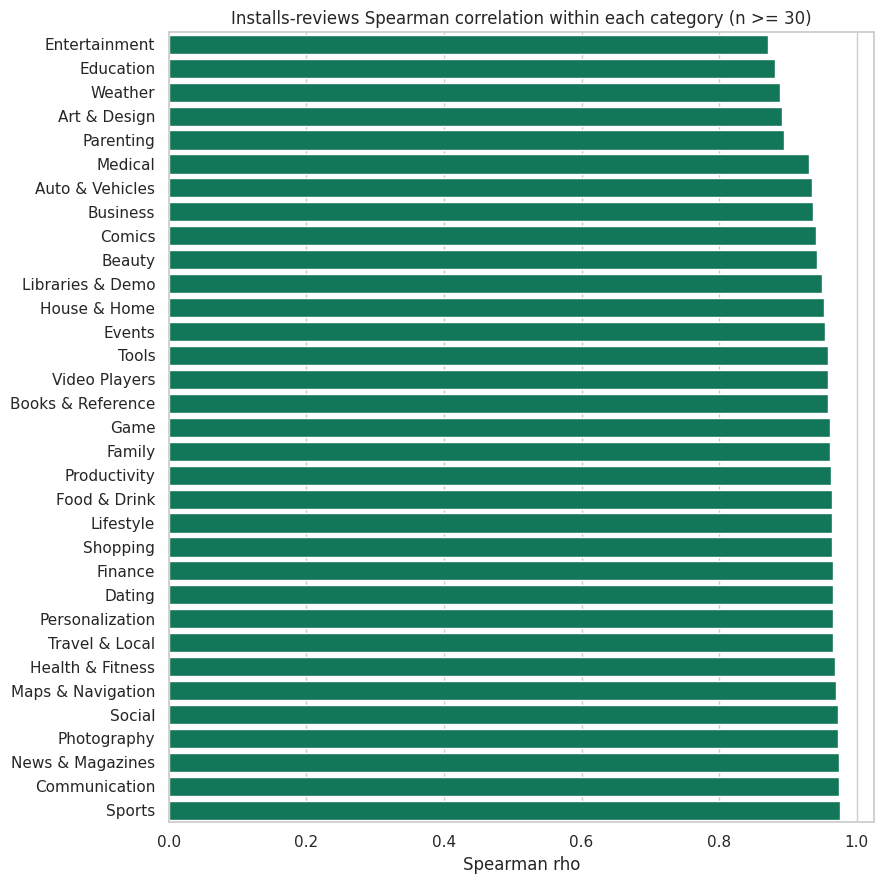

Within-category Pearson correlation (log scale, category means removed): 0.955


,apps,spearman_rho,median_reviews_per_1k_installs
type,,,
Free,8905,0.971,15.640
Paid,754,0.958,60.500


In [23]:
# RQ1 step 5a. Does the relationship hold inside each category? (rules out a category-mix explanation)
def category_spearman(df: pd.DataFrame, min_n: int = MIN_N) -> pd.DataFrame:
    rows = []
    for cat, g in df.groupby("category"):
        if len(g) >= min_n and g["installs"].nunique() > 1 and g["reviews"].nunique() > 1:
            rows.append((cat, len(g), stats.spearmanr(g["installs"], g["reviews"])[0]))
    return pd.DataFrame(rows, columns=["category", "apps", "spearman_rho"]).sort_values("spearman_rho")

cat_corr = category_spearman(clean_df)
display(cat_corr.describe().loc[["count", "min", "50%", "max"], ["apps", "spearman_rho"]])

fig, ax = plt.subplots(figsize=(9, 9))
sns.barplot(data=cat_corr, y="category", x="spearman_rho", color=GREEN, ax=ax)
ax.set_title(f"Installs-reviews Spearman correlation within each category (n >= {MIN_N})")
ax.set_xlabel("Spearman rho"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/04_category_correlation.png", dpi=150)
plt.show()

# Within-category (demeaned) correlation on the log scale
x_w = clean_df["log10_installs"] - clean_df.groupby("category")["log10_installs"].transform("mean")
y_w = clean_df["log10_reviews"] - clean_df.groupby("category")["log10_reviews"].transform("mean")
r_within = float(np.corrcoef(x_w, y_w)[0, 1])
print(f"Within-category Pearson correlation (log scale, category means removed): {r_within:.3f}")

# RQ1 step 5b. Free vs. paid
type_rows = []
for t, g in clean_df.groupby("type"):
    type_rows.append({"type": t, "apps": len(g),
                      "spearman_rho": stats.spearmanr(g["installs"], g["reviews"])[0],
                      "median_reviews_per_1k_installs": g["reviews_per_1k_installs"].median()})
type_corr = pd.DataFrame(type_rows).set_index("type")
display(type_corr)

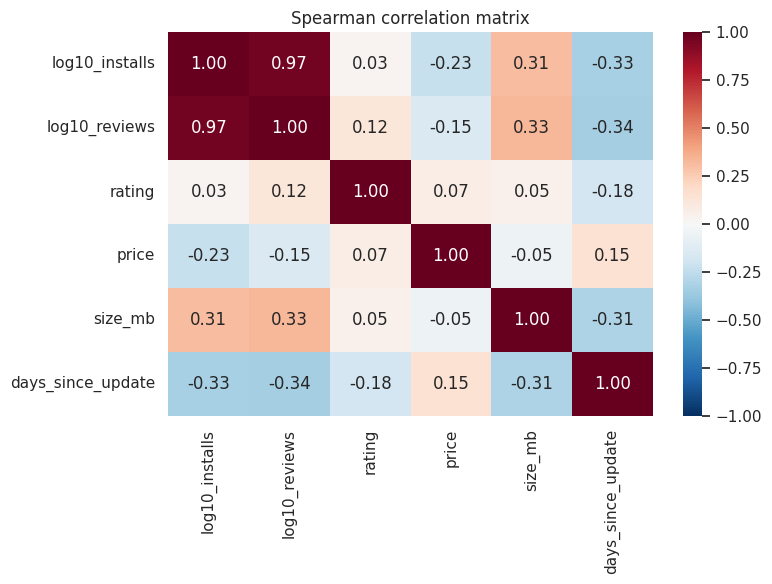

,spearman_with_installs,strength
log10_reviews,0.968,very strong
days_since_update,-0.332,weak
size_mb,0.310,weak
price,-0.232,weak
rating,0.027,negligible


In [24]:
# RQ1 step 6. How do other app attributes relate to installs? (Spearman handles skew and non-linearity)
cols = ["log10_installs", "log10_reviews", "rating", "price", "size_mb", "days_since_update"]
matrix = clean_df[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/05_correlation_matrix.png", dpi=150)
plt.show()

ranked = (matrix["log10_installs"].drop("log10_installs")
          .to_frame("spearman_with_installs")
          .assign(strength=lambda d: d["spearman_with_installs"].map(strength_label),
                  abs_rho=lambda d: d["spearman_with_installs"].abs())
          .sort_values("abs_rho", ascending=False).drop(columns="abs_rho"))
display(ranked)

In [25]:
# RQ1 step 7. Outliers: apps far above or below the regression line
df_res = clean_df.copy()
df_res["expected_log_reviews"] = lr.intercept + lr.slope * df_res["log10_installs"]
df_res["residual"] = df_res["log10_reviews"] - df_res["expected_log_reviews"]
df_res["expected_reviews"] = (10 ** df_res["expected_log_reviews"] - 1).round(0)

pool = df_res[df_res["installs"] >= 1_000]          # ignore tiny apps where rates are noisy
show_cols = ["app", "category", "installs", "reviews", "expected_reviews", "residual"]

print("More reviews than their installs predict (highly engaged audiences):")
display(pool.nlargest(10, "residual")[show_cols])

print("Fewer reviews than their installs predict (installed widely, rarely reviewed):")
display(pool.nsmallest(10, "residual")[show_cols])

resid_sd = df_res["residual"].std()
print(f"Residual standard deviation (log10 units): {resid_sd:.3f} "
      f"-> typical app is within a factor of {10 ** resid_sd:.1f}x of the model's prediction")

More reviews than their installs predict (highly engaged audiences):


,app,category,installs,reviews,expected_reviews,residual
9129,Alarmy (Sleep If U Can) - Pro,Lifestyle,10000,10249,237.000,1.635
4253,Clash of Clans,Game,100000000,44893888,"1,091,466.000",1.614
1579,ai.type keyboard Plus + Emoji,Tools,100000,57076,"1,955.000",1.465
2383,Be Stronger,Health & Fitness,1000,787,28.000,1.436
9155,My Movies Pro - Movie & TV Collection Library,Lifestyle,10000,6477,237.000,1.436
8126,Day R Premium,Family,100000,51068,"1,955.000",1.417
6053,BZ Reminder PRO,Business,1000,726,28.000,1.401
7779,Carrier Landings Pro,Family,10000,5969,237.000,1.400
8244,Ski Safari: Adventure Time,Family,100000,48754,"1,955.000",1.397
4742,Flud (Ad free),Video Players,10000,5639,237.000,1.376


Fewer reviews than their installs predict (installed widely, rarely reviewed):


,app,category,installs,reviews,expected_reviews,residual
1617,Android TV Remote Service,Tools,1000000,1,"16,100.000",-3.906
1786,Google app for Android TV,Tools,10000000,66,"132,566.000",-3.296
460,Nougat Android 7 Launcher : AW,Personalization,100000,0,"1,955.000",-3.291
8158,Explora con el Chavo,Family,100000,0,"1,955.000",-3.291
3580,Simple x3DS Emulator - BETA,Game,50000,0,"1,036.000",-3.016
7946,AQ: First Contact,Family,50000,0,"1,036.000",-3.016
7947,AR Dragon Pet,Family,50000,0,"1,036.000",-3.016
131,SH-02J Owner's Manual (Android 8.0),Books & Reference,50000,2,"1,036.000",-2.539
2413,"Period Tracker, Pregnancy Calculator & Calendar 🌸",Health & Fitness,10000,0,237.000,-2.376
2795,DW,News & Magazines,10000,0,237.000,-2.376


Residual standard deviation (log10 units): 0.516 -> typical app is within a factor of 3.3x of the model's prediction


In [26]:
# ANSWER RQ1: generated from the computed results above (no hard-coded numbers)
rho_pearson_log = float(corr_df.loc["Pearson (log10)", "coefficient"])
rho_pearson_raw = float(corr_df.loc["Pearson (raw)", "coefficient"])
kendall = float(corr_df.loc["Kendall tau-b", "coefficient"])
cat_share_positive = (cat_corr["spearman_rho"] > 0).mean()

strongest_overall = ranked.index[0]
others = ranked.drop(index="log10_reviews", errors="ignore")
top_other_name, top_other = others.index[0], others.iloc[0]
rate_pool = bucket_stats[bucket_stats["installs_min"] >= 1_000]["median_reviews_per_1k_installs"]

direction = "positive" if rho_s > 0 else "negative"
if abs(rho_s) < 0.2:
    verdict = f"**There is no meaningful relationship** between installs and reviews (Spearman rho = {rho_s:.2f})."
else:
    verdict = f"**Yes: installs and reviews have a {strength_label(rho_s)} {direction} relationship.**"

ANSWERS["RQ1"] = (f"{strength_label(rho_s).capitalize()} {direction} relationship: Spearman rho = {rho_s:.2f} "
                  f"(95% CI {ci_lo:.2f} to {ci_hi:.2f}); each 10x more installs goes with about {10 ** lr.slope:.1f}x more reviews "
                  f"(R² = {lr.rvalue**2:.2f}); positive in {cat_share_positive:.0%} of categories.")

display(Markdown(f"""
### Answer to RQ1

{verdict}

- **Rank correlation:** Spearman rho = **{rho_s:.2f}** (bootstrap 95% CI {ci_lo:.2f} to {ci_hi:.2f}); Kendall tau-b = {kendall:.2f}.
- **Log scale:** Pearson r = **{rho_pearson_log:.2f}**. On raw counts Pearson r is {rho_pearson_raw:.2f}; raw values are distorted by a few blockbuster apps, so log and rank methods are the main evidence.
- **Effect size:** the log-log slope is **{lr.slope:.2f}** (95% CI {slope_ci[0]:.2f} to {slope_ci[1]:.2f}), R² = {lr.rvalue**2:.2f}. Each 10x increase in installs goes with roughly a **{10 ** lr.slope:.1f}x** increase in reviews.
- **Review rate across install levels (1K+ installs):** the median ranges from {rate_pool.min():.2f} to {rate_pool.max():.2f} reviews per 1,000 installs. Median reviews {'increase at every step' if monotonic else 'do not increase at every step'} of the install ladder.
- **Not a category artifact:** positive in {cat_share_positive:.0%} of categories with at least {MIN_N} apps (median within-category rho = {cat_corr['spearman_rho'].median():.2f}); within-category log correlation is {r_within:.2f}.
- **Compared with other attributes:** the strongest correlate of installs is `{strongest_overall}`. The strongest *non-review* attribute is `{top_other_name}` (Spearman {top_other['spearman_with_installs']:.2f}, {top_other['strength']}).
- **Robustness:** excluding zero-review apps gives Spearman rho = {rho_nz:.2f}.
"""))


### Answer to RQ1

**Yes: installs and reviews have a very strong positive relationship.**

- **Rank correlation:** Spearman rho = **0.97** (bootstrap 95% CI 0.97 to 0.97); Kendall tau-b = 0.87.
- **Log scale:** Pearson r = **0.96**. On raw counts Pearson r is 0.63; raw values are distorted by a few blockbuster apps, so log and rank methods are the main evidence.
- **Effect size:** the log-log slope is **0.92** (95% CI 0.91 to 0.92), R² = 0.92. Each 10x increase in installs goes with roughly a **8.2x** increase in reviews.
- **Review rate across install levels (1K+ installs):** the median ranges from 8.63 to 29.55 reviews per 1,000 installs. Median reviews increase at every step of the install ladder.
- **Not a category artifact:** positive in 100% of categories with at least 30 apps (median within-category rho = 0.96); within-category log correlation is 0.96.
- **Compared with other attributes:** the strongest correlate of installs is `log10_reviews`. The strongest *non-review* attribute is `days_since_update` (Spearman -0.33, weak).
- **Robustness:** excluding zero-review apps gives Spearman rho = 0.96.


**Caveats that apply to every RQ1 number**
- **Correlation is not causation.** Reviews and installs likely influence each other: more installs create more people who *can* review, and visible reviews can attract installs.
- **Installs are bucketed**, so slopes are approximate and rank correlations include many ties.
- **Cumulative, not time-aware.** Older apps have had more time to gather both, a confounder only partly captured by `days_since_update`.
- **Snapshot and sample.** The data is a one-time scrape and may not represent the full store.

---
## RQ2. Which categories have the best ratings?

**H1:** median ratings differ across categories. **Method:** Kruskal-Wallis across categories (rank-based, since ratings are bounded and skewed), epsilon-squared effect size, and bootstrap 95% CIs for each category median. **Selection check first:** ratings are missing for some apps, so we test whether unrated apps differ in popularity.

,group,apps,median_installs,median_reviews
0,Rated apps,8196,"100,000.000","3,017.000"
1,Unrated apps,1463,100.000,1.000


Unrated apps hold 15.1% of listings. Cliff's delta (unrated vs rated installs) = -0.88 (large): unrated apps are much less installed, so rating results describe apps with enough reviews to be rated.


,category,rated_apps,median_rating,mean_rating,ci_low,ci_high,pct_4_5_plus,median_installs,total_installs
0,Events,45,4.500,4.436,4.400,4.600,53.333,"50,000.000",15949410
1,Books & Reference,169,4.500,4.345,4.400,4.500,51.479,"100,000.000",1665791655
2,Health & Fitness,244,4.500,4.243,4.400,4.500,51.230,"500,000.000",1144006220
3,Art & Design,59,4.400,4.359,4.200,4.500,42.373,"100,000.000",113233100
4,Education,106,4.400,4.355,4.300,4.400,39.623,"1,000,000.000",189852000
5,Personalization,298,4.400,4.332,4.300,4.400,39.933,"100,000.000",1532352930
6,Parenting,50,4.400,4.300,4.200,4.600,46.000,"100,000.000",31116110
7,Comics,54,4.400,4.181,4.100,4.450,37.037,"100,000.000",44931100
8,Beauty,42,4.300,4.279,4.100,4.500,38.095,"100,000.000",26916200
9,Social,203,4.300,4.247,4.200,4.300,31.527,"500,000.000",5487841475


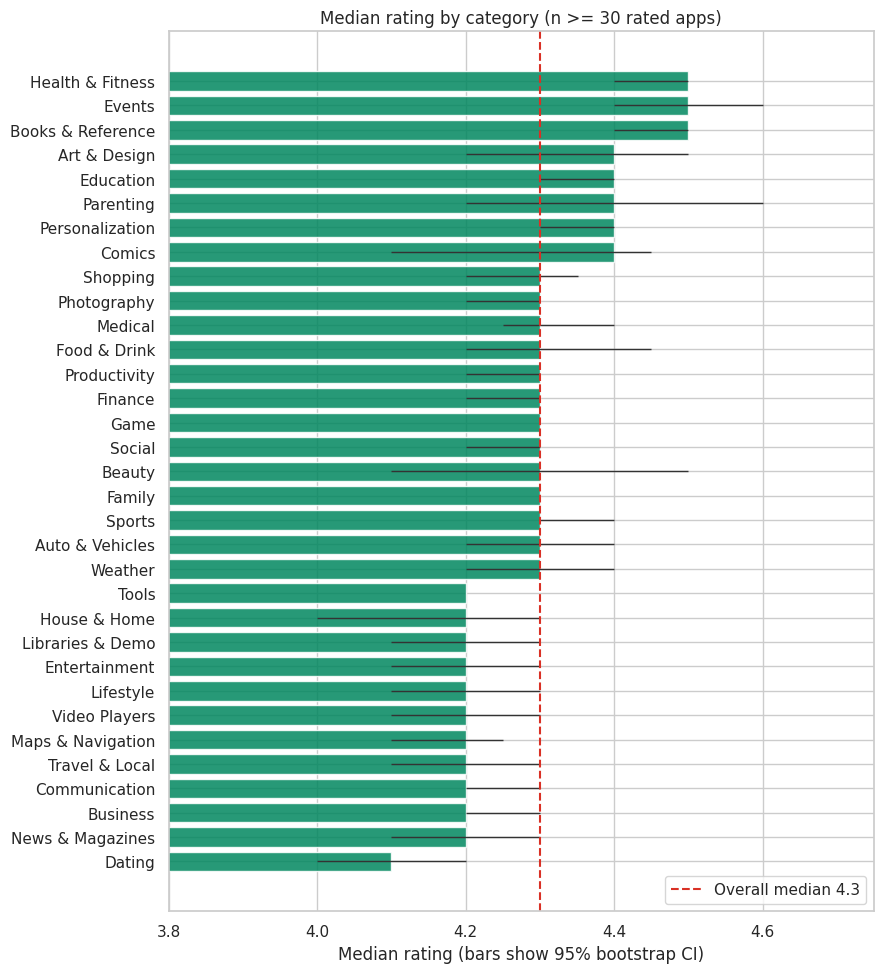


### Answer to RQ2

- **Best-rated categories (median, then mean):** Events (4.5, n=45), Books & Reference (4.5, n=169), Health & Fitness (4.5, n=244).
- **Lowest-rated:** Tools (4.2, n=720), Maps & Navigation (4.2, n=118), Dating (4.1, n=133).
- **Do categories really differ?** Kruskal-Wallis H = 238.8, p = 1.71e-33; epsilon² = **0.025** (small effect). The top and bottom category CIs do not overlap.
- **Strong on both rating and reach** (top quartile of each): Education, Game, Weather, Shopping, Food & Drink, Photography.
- **Caution:** medians of 1-5 ratings are coarse (many ties), so means and the share of 4.5+ apps are shown in the table. Ratings exist only for apps that attracted reviews (see selection check above).


In [27]:
rated = clean_df.dropna(subset=["rating"]).copy()
unrated = clean_df[clean_df["rating"].isna()]

# Selection check: are unrated apps systematically less popular?
delta_miss = cliffs_delta(unrated["installs"], rated["installs"])
sel = pd.DataFrame({
    "group": ["Rated apps", "Unrated apps"],
    "apps": [len(rated), len(unrated)],
    "median_installs": [rated["installs"].median(), unrated["installs"].median()],
    "median_reviews": [rated["reviews"].median(), unrated["reviews"].median()],
})
display(sel)
print(f"Unrated apps hold {len(unrated) / len(clean_df):.1%} of listings. Cliff's delta (unrated vs rated installs) = "
      f"{delta_miss:.2f} ({delta_label(delta_miss)}): "
      f"{'unrated apps are much less installed, so rating results describe apps with enough reviews to be rated' if delta_miss < -0.33 else 'selection effect is limited'}.")

def category_rating_table(df: pd.DataFrame, min_n: int = MIN_N) -> pd.DataFrame:
    """Per-category rating summary with bootstrap CI for the median."""
    rows = []
    for cat, g in df.groupby("category"):
        if len(g) >= min_n:
            lo, hi = bootstrap_median_ci(g["rating"])
            rows.append(dict(category=cat, rated_apps=len(g), median_rating=g["rating"].median(),
                             mean_rating=g["rating"].mean(), ci_low=lo, ci_high=hi,
                             pct_4_5_plus=(g["rating"] >= 4.5).mean() * 100,
                             median_installs=g["installs"].median(), total_installs=g["installs"].sum()))
    return (pd.DataFrame(rows).sort_values(["median_rating", "mean_rating"], ascending=False)
            .reset_index(drop=True))

ct = category_rating_table(rated)
display(ct.head(10))

groups = [g["rating"].to_numpy() for _, g in rated.groupby("category") if len(g) >= MIN_N]
H, p_kw, eps2 = epsilon_squared(groups)

order = ct.sort_values("median_rating")
fig, ax = plt.subplots(figsize=(9, max(5, 0.3 * len(order))))
err = [(order["median_rating"] - order["ci_low"]).clip(lower=0), (order["ci_high"] - order["median_rating"]).clip(lower=0)]
ax.barh(order["category"], order["median_rating"], xerr=err, color=GREEN, alpha=0.85, error_kw=dict(ecolor="#333", lw=1))
ax.axvline(rated["rating"].median(), color=RED, ls="--", label=f"Overall median {rated['rating'].median():.1f}")
ax.set_xlim(max(1, order["ci_low"].min() - 0.2), min(5, order["ci_high"].max() + 0.15))
ax.set_xlabel("Median rating (bars show 95% bootstrap CI)"); ax.set_ylabel("")
ax.set_title(f"Median rating by category (n >= {MIN_N} rated apps)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/06_category_ratings.png", dpi=150); plt.show()

# Categories that are strong on BOTH rating and reach (top quartile each)
q_rating, q_inst = ct["median_rating"].quantile(0.75), ct["median_installs"].quantile(0.75)
both = ct[(ct["median_rating"] >= q_rating) & (ct["median_installs"] >= q_inst)]["category"].tolist()

top3, bot3 = ct.head(3), ct.tail(3)
separable = ct.iloc[0]["ci_low"] > ct.iloc[-1]["ci_high"]
ANSWERS["RQ2"] = (f"Highest median ratings: {', '.join(top3['category'])} ({top3['median_rating'].iloc[0]:.1f}); lowest: "
                  f"{', '.join(bot3['category'])} ({bot3['median_rating'].iloc[-1]:.1f}). Category explains "
                  f"{eps2:.1%} of rating rank variance ({eps2_label(eps2)} effect).")

display(Markdown(f"""
### Answer to RQ2

- **Best-rated categories (median, then mean):** {', '.join(f"{r.category} ({r.median_rating:.1f}, n={r.rated_apps})" for r in top3.itertuples())}.
- **Lowest-rated:** {', '.join(f"{r.category} ({r.median_rating:.1f}, n={r.rated_apps})" for r in bot3.itertuples())}.
- **Do categories really differ?** Kruskal-Wallis H = {H:.1f}, p = {fmt_p(p_kw)}; epsilon² = **{eps2:.3f}** ({eps2_label(eps2)} effect). The top and bottom category CIs {'do not overlap' if separable else 'overlap'}.
- **Strong on both rating and reach** (top quartile of each): {', '.join(both) if both else 'no category is in the top quartile of both'}.
- **Caution:** medians of 1-5 ratings are coarse (many ties), so means and the share of 4.5+ apps are shown in the table. Ratings exist only for apps that attracted reviews (see selection check above).
"""))

---
## RQ3. Do paid apps earn higher ratings than free apps?

**H1:** paid apps are rated higher. **Method:** Mann-Whitney U with Cliff's delta, a bootstrap CI for the median difference, then a **category-adjusted** comparison (ratings minus their category mean) so that a different category mix cannot explain the result.

,apps,mean,median,std
type,,,,
Free,7594,4.166,4.300,0.534
Paid,602,4.262,4.400,0.557


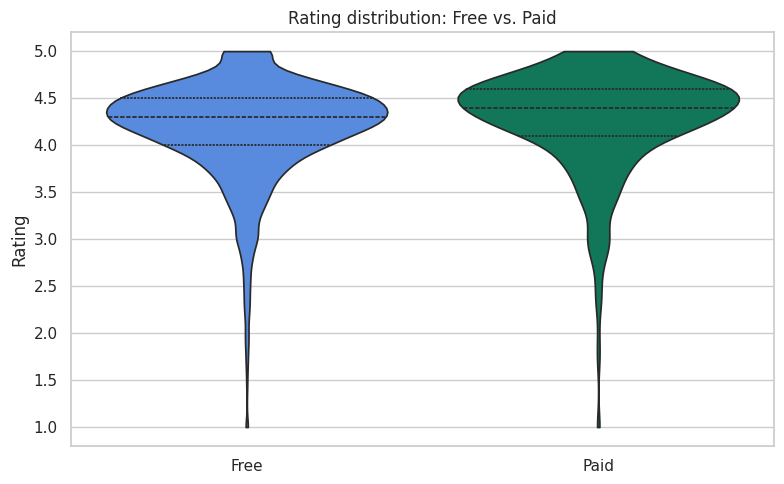


### Answer to RQ3

- Paid apps (n=602) have a mean rating of **4.26** vs. **4.17** for free apps (n=7,594): paid apps are rated **higher** by 0.10 points.
- **Median difference:** +0.10 (95% bootstrap CI +0.10 to +0.10).
- **Test:** Mann-Whitney p = 8.11e-11; **Cliff's delta = 0.16 (small)**. A small effect means a randomly chosen paid app beats a randomly chosen free app in rating about 58% of the time (50% = no difference).
- **Category-adjusted** delta = 0.14 (negligible), so category mix explains little of the gap.
- **Within categories** (>= 15 apps of each type, 10 categories): paid apps have the higher mean rating in 80% of them.
- **Interpretation:** paying filters for motivated users and selects apps that charge because they are niche or specialised; it does not show that charging *causes* better ratings.


In [28]:
free_r = rated.loc[~rated["is_paid"], "rating"]
paid_r = rated.loc[rated["is_paid"], "rating"]

mw = stats.mannwhitneyu(paid_r, free_r, alternative="two-sided")
d3 = cliffs_delta(paid_r, free_r)
med_diff = paid_r.median() - free_r.median()
diff_lo, diff_hi = bootstrap_median_diff_ci(paid_r, free_r)
mean_diff = paid_r.mean() - free_r.mean()

# Category-adjusted: remove each category's mean rating, then compare again
rated["rating_adj"] = rated["rating"] - rated.groupby("category")["rating"].transform("mean")
adj_paid = rated.loc[rated["is_paid"], "rating_adj"]; adj_free = rated.loc[~rated["is_paid"], "rating_adj"]
d3_adj = cliffs_delta(adj_paid, adj_free)

# Within-category: how many categories (>=15 apps of each type) have paid > free?
rows = []
for cat, g in rated.groupby("category"):
    a, b = g.loc[g["is_paid"], "rating"], g.loc[~g["is_paid"], "rating"]
    if len(a) >= 15 and len(b) >= 15:
        rows.append((cat, len(a), len(b), a.median() - b.median(), a.mean() - b.mean()))
within3 = pd.DataFrame(rows, columns=["category", "paid_n", "free_n", "median_diff", "mean_diff"])
share_paid_higher = (within3["mean_diff"] > 0).mean() if len(within3) else float("nan")

summary3 = rated.groupby("type")["rating"].agg(apps="count", mean="mean", median="median", std="std")
display(summary3)

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=rated, x="type", y="rating", order=["Free", "Paid"], palette=[BLUE, GREEN], inner="quartile", cut=0, ax=ax, hue="type", legend=False)
ax.set_title("Rating distribution: Free vs. Paid"); ax.set_xlabel(""); ax.set_ylabel("Rating")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/07_rating_free_vs_paid.png", dpi=150); plt.show()

better = "higher" if mean_diff > 0 else "lower"
ANSWERS["RQ3"] = (f"Paid apps average {mean_diff:+.2f} rating points vs. free (median diff {med_diff:+.2f}); "
                  f"Cliff's delta {d3:.2f} ({delta_label(d3)}); after category adjustment {d3_adj:.2f} ({delta_label(d3_adj)}).")

display(Markdown(f"""
### Answer to RQ3

- Paid apps (n={len(paid_r):,}) have a mean rating of **{paid_r.mean():.2f}** vs. **{free_r.mean():.2f}** for free apps (n={len(free_r):,}): paid apps are rated **{better}** by {abs(mean_diff):.2f} points.
- **Median difference:** {med_diff:+.2f} (95% bootstrap CI {diff_lo:+.2f} to {diff_hi:+.2f}).
- **Test:** Mann-Whitney p = {fmt_p(mw.pvalue)}; **Cliff's delta = {d3:.2f} ({delta_label(d3)})**. A {delta_label(d3)} effect means a randomly chosen paid app beats a randomly chosen free app in rating about {(d3 + 1) / 2:.0%} of the time (50% = no difference).
- **Category-adjusted** delta = {d3_adj:.2f} ({delta_label(d3_adj)}), so category mix {'explains little of' if abs(d3_adj) > 0.8 * abs(d3) else 'explains part of'} the gap.
- **Within categories** (>= 15 apps of each type, {len(within3)} categories): paid apps have the higher mean rating in {share_paid_higher:.0%} of them.
- **Interpretation:** paying filters for motivated users and selects apps that charge because they are niche or specialised; it does not show that charging *causes* better ratings.
"""))

---
## RQ4. How does app size relate to installs and ratings?

**H1:** larger apps have fewer installs (download friction, storage limits). **Method:** Spearman correlation on apps with a known size, size bands, a category-adjusted check, and a comparison against apps whose size "varies with device" (those are often large, popular apps).

,size_band,apps,median_installs,median_rating,pct_1m_plus
0,<5 MB,2263,"5,000.000",4.200,13.522
1,5-15 MB,2384,"10,000.000",4.300,25.336
2,15-30 MB,1800,"50,000.000",4.300,33.333
3,30-60 MB,1353,"500,000.000",4.300,45.455
4,60+ MB,631,"1,000,000.000",4.300,58.003
5,Varies with device,1228,"5,000,000.000",4.300,73.860


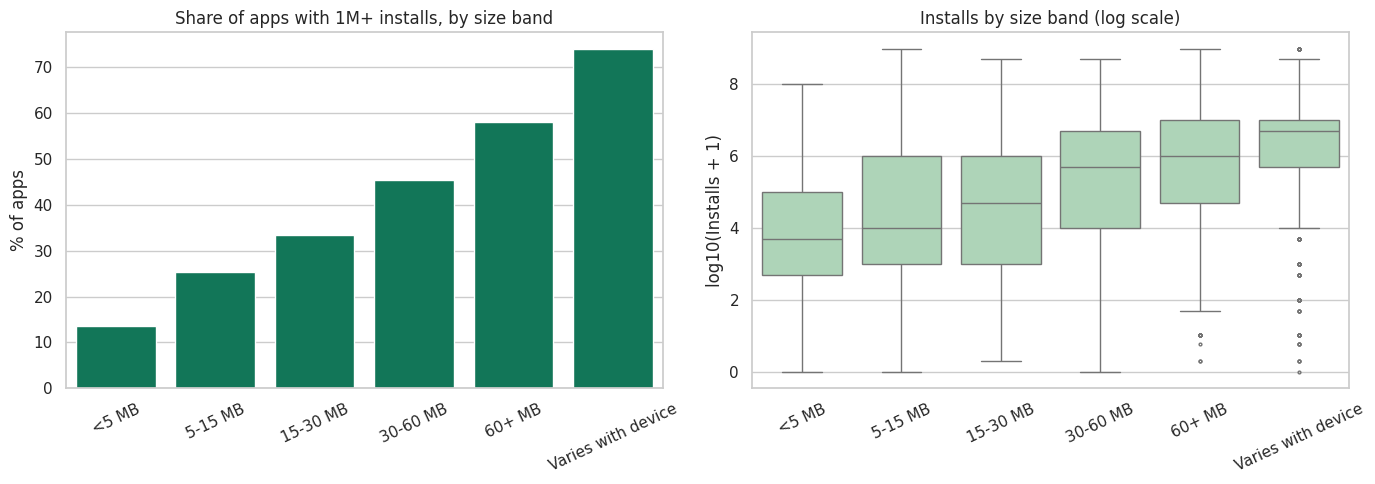


### Answer to RQ4

- **Size vs. installs:** Spearman rho = **0.31** (weak, positive; p = 2.13e-187, n = 8,431). Category-adjusted log correlation = 0.24.
- **Size vs. ratings:** rho = 0.05 (negligible); **size vs. reviews:** rho = 0.33.
- **Where success concentrates:** the share of apps with 1M+ installs is highest in the **60+ MB** band (58.0%) and lowest in the **<5 MB** band (13.5%).
- **"Varies with device" apps** (n=1,228) have a median of 5,000,000 installs vs. 50,000 for apps with a fixed size (Cliff's delta = 0.56, large).
- **Reading:** the hypothesis that bigger means fewer installs is not supported by the rank correlation (larger apps tend to be installed more). Size is likely a proxy for app complexity and category, so it should not be read as a direct download penalty.


In [29]:
sized = clean_df.dropna(subset=["size_mb"]).copy()
rho_si = stats.spearmanr(sized["size_mb"], sized["installs"])
rho_sr = stats.spearmanr(sized.dropna(subset=["rating"])["size_mb"], sized.dropna(subset=["rating"])["rating"])
rho_sv = stats.spearmanr(sized["size_mb"], sized["reviews"])

# Category-adjusted correlation on the log scale
xs_ = sized["log10_size_mb"] - sized.groupby("category")["log10_size_mb"].transform("mean")
ys_ = sized["log10_installs"] - sized.groupby("category")["log10_installs"].transform("mean")
r_size_within = float(np.corrcoef(xs_, ys_)[0, 1])

size_stats = (clean_df.groupby("size_band", observed=True)
              .agg(apps=("app", "count"), median_installs=("installs", "median"),
                   median_rating=("rating", "median"),
                   pct_1m_plus=("installs", lambda s: (s >= 1_000_000).mean() * 100))
              .reset_index())
display(size_stats)

varies = clean_df[clean_df["size_missing"]]
d4 = cliffs_delta(varies["installs"], sized["installs"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=size_stats, x="size_band", y="pct_1m_plus", color=GREEN, ax=axes[0])
axes[0].set_title("Share of apps with 1M+ installs, by size band"); axes[0].set_xlabel(""); axes[0].set_ylabel("% of apps")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=clean_df, x="size_band", y="log10_installs", color="#a8dab5", fliersize=2, ax=axes[1])
axes[1].set_title("Installs by size band (log scale)"); axes[1].set_xlabel(""); axes[1].set_ylabel("log10(Installs + 1)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/08_size_vs_installs.png", dpi=150); plt.show()

known = size_stats[size_stats["size_band"] != "Varies with device"]
peak_band = known.loc[known["pct_1m_plus"].idxmax(), "size_band"]
shape = ("positive" if rho_si[0] > 0 else "negative")
ANSWERS["RQ4"] = (f"Size vs. installs: Spearman rho = {rho_si[0]:.2f} ({strength_label(rho_si[0])} {shape}); "
                  f"1M+ install share peaks in the {peak_band} band; size vs. rating rho = {rho_sr[0]:.2f}.")

display(Markdown(f"""
### Answer to RQ4

- **Size vs. installs:** Spearman rho = **{rho_si[0]:.2f}** ({strength_label(rho_si[0])}, {shape}; p = {fmt_p(rho_si[1])}, n = {len(sized):,}). Category-adjusted log correlation = {r_size_within:.2f}.
- **Size vs. ratings:** rho = {rho_sr[0]:.2f} ({strength_label(rho_sr[0])}); **size vs. reviews:** rho = {rho_sv[0]:.2f}.
- **Where success concentrates:** the share of apps with 1M+ installs is highest in the **{peak_band}** band ({known['pct_1m_plus'].max():.1f}%) and lowest in the **{known.loc[known['pct_1m_plus'].idxmin(), 'size_band']}** band ({known['pct_1m_plus'].min():.1f}%).
- **"Varies with device" apps** (n={len(varies):,}) have a median of {varies['installs'].median():,.0f} installs vs. {sized['installs'].median():,.0f} for apps with a fixed size (Cliff's delta = {d4:.2f}, {delta_label(d4)}).
- **Reading:** the hypothesis that bigger means fewer installs is {'supported' if rho_si[0] <= -0.2 else 'not supported'} by the rank correlation ({'larger apps tend to be installed less' if rho_si[0] <= -0.2 else 'larger apps tend to be installed more' if rho_si[0] >= 0.2 else 'size has little rank relationship with installs'}). Size is likely a proxy for app complexity and category, so it should not be read as a direct download penalty.
"""))

---
## RQ5. How does price relate to installs?

**H1:** higher price goes with fewer installs. **Method:** Mann-Whitney (free vs. paid installs) with Cliff's delta, Spearman among paid apps only, price bands, and an outlier check for absurd prices.

,price_band,apps,median_installs,pct_100k_plus,median_rating
0,Free,8905,"100,000.000",55.025,4.300
1,$0.01-0.99,145,500.000,10.345,4.400
2,$1-2.99,293,"1,000.000",16.041,4.400
3,$3-9.99,241,"5,000.000",19.917,4.400
4,$10+,75,"1,000.000",6.667,4.200


Apps priced at $100 or more: 20 (novelty / outlier listings; they barely move rank-based results).


,app,category,price,installs
9151,I'm Rich - Trump Edition,Lifestyle,400.000,10000
2048,I AM RICH PRO PLUS,Finance,399.990,1000
2049,I am Rich!,Finance,399.990,1000
2050,I am rich (Most expensive app),Finance,399.990,1000
2075,I am Rich,Finance,399.990,5000


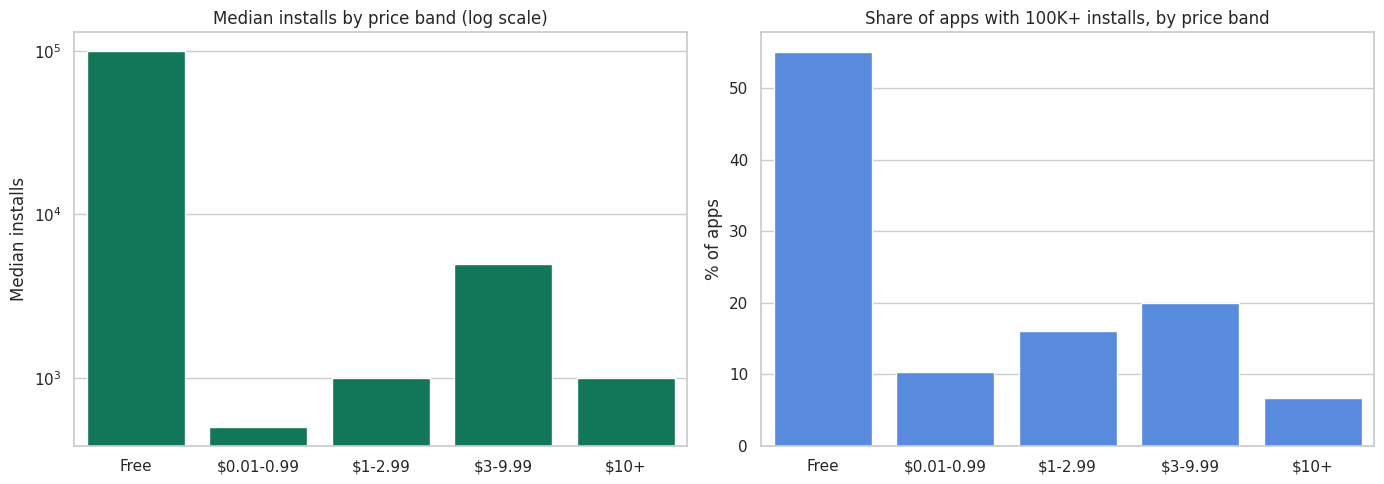


### Answer to RQ5

- **Free vs. paid reach:** free apps have a median of **100,000** installs vs. **1,000** for paid apps (8,905 vs. 754 apps). Mann-Whitney p = 7.96e-116; **Cliff's delta = 0.50 (large)**: a random free app out-installs a random paid app about 75% of the time.
- **Within paid apps:** price vs. installs Spearman rho = **0.13** (negligible, n = 754); price vs. rating rho = -0.07.
- **Price bands:** the share of paid apps with 100K+ installs ranges from 6.7% to 19.9%, versus 55.0% for free apps.
- **Reading:** charging at all goes with clearly lower reach; among paid apps, price level has little rank relationship with installs.


In [30]:
paid = clean_df[clean_df["is_paid"]]
free = clean_df[~clean_df["is_paid"]]

mw5 = stats.mannwhitneyu(free["installs"], paid["installs"], alternative="two-sided")
d5 = cliffs_delta(free["installs"], paid["installs"])
rho_pp = stats.spearmanr(paid["price"], paid["installs"])
rho_pr = stats.spearmanr(paid["price"], paid["rating"].fillna(paid["rating"].median()))

price_stats = (clean_df.groupby("price_band", observed=True)
               .agg(apps=("app", "count"), median_installs=("installs", "median"),
                    pct_100k_plus=("installs", lambda s: (s >= 100_000).mean() * 100),
                    median_rating=("rating", "median"))
               .reset_index())
display(price_stats)

expensive = clean_df[clean_df["price"] >= 100]
print(f"Apps priced at $100 or more: {len(expensive)} (novelty / outlier listings; they barely move rank-based results).")
display(expensive.nlargest(5, "price")[["app", "category", "price", "installs"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=price_stats, x="price_band", y="median_installs", color=GREEN, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Median installs by price band (log scale)")
axes[0].set_xlabel(""); axes[0].set_ylabel("Median installs")
sns.barplot(data=price_stats, x="price_band", y="pct_100k_plus", color=BLUE, ax=axes[1])
axes[1].set_title("Share of apps with 100K+ installs, by price band"); axes[1].set_xlabel(""); axes[1].set_ylabel("% of apps")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/09_price_vs_installs.png", dpi=150); plt.show()

paid_bands = price_stats[price_stats["price_band"] != "Free"]
ANSWERS["RQ5"] = (f"Free apps have a median of {free['installs'].median():,.0f} installs vs. {paid['installs'].median():,.0f} for paid "
                  f"(Cliff's delta {d5:.2f}, {delta_label(d5)}); among paid apps price vs. installs rho = {rho_pp[0]:.2f}.")

display(Markdown(f"""
### Answer to RQ5

- **Free vs. paid reach:** free apps have a median of **{free['installs'].median():,.0f}** installs vs. **{paid['installs'].median():,.0f}** for paid apps ({len(free):,} vs. {len(paid):,} apps). Mann-Whitney p = {fmt_p(mw5.pvalue)}; **Cliff's delta = {d5:.2f} ({delta_label(d5)})**: a random free app out-installs a random paid app about {(d5 + 1) / 2:.0%} of the time.
- **Within paid apps:** price vs. installs Spearman rho = **{rho_pp[0]:.2f}** ({strength_label(rho_pp[0])}, n = {len(paid):,}); price vs. rating rho = {rho_pr[0]:.2f}.
- **Price bands:** the share of paid apps with 100K+ installs ranges from {paid_bands['pct_100k_plus'].min():.1f}% to {paid_bands['pct_100k_plus'].max():.1f}%, versus {price_stats.loc[price_stats['price_band'] == 'Free', 'pct_100k_plus'].iloc[0]:.1f}% for free apps.
- **Reading:** {'charging at all goes with clearly lower reach' if d5 >= 0.33 else 'charging goes with modestly lower reach' if d5 >= 0.147 else 'there is no meaningful reach gap between free and paid apps'}; among paid apps, {'higher prices go with fewer installs' if rho_pp[0] <= -0.2 else 'price level has little rank relationship with installs'}.
"""))

---
## RQ6. How do installs and ratings vary with update recency?

**H1:** recently updated apps have more installs and higher ratings. **Method:** Spearman correlations, recency bands, and the share of recently updated apps in each install tier. Recency is measured from the newest update date in the dataset.

,recency_band,apps,median_installs,median_rating,mean_rating,pct_1m_plus
0,0-30 days,2936,"1,000,000.000",4.400,4.270,56.744
1,31-90 days,1829,"100,000.000",4.300,4.208,38.928
2,91-365 days,2478,"10,000.000",4.200,4.131,23.164
3,1-2 years,1205,"10,000.000",4.200,4.064,18.174
4,2+ years,1211,"10,000.000",4.200,4.052,18.745


,install_tier,pct_updated_within_180d
0,<10K,49.221
1,10K-1M,55.359
2,1M+,77.987


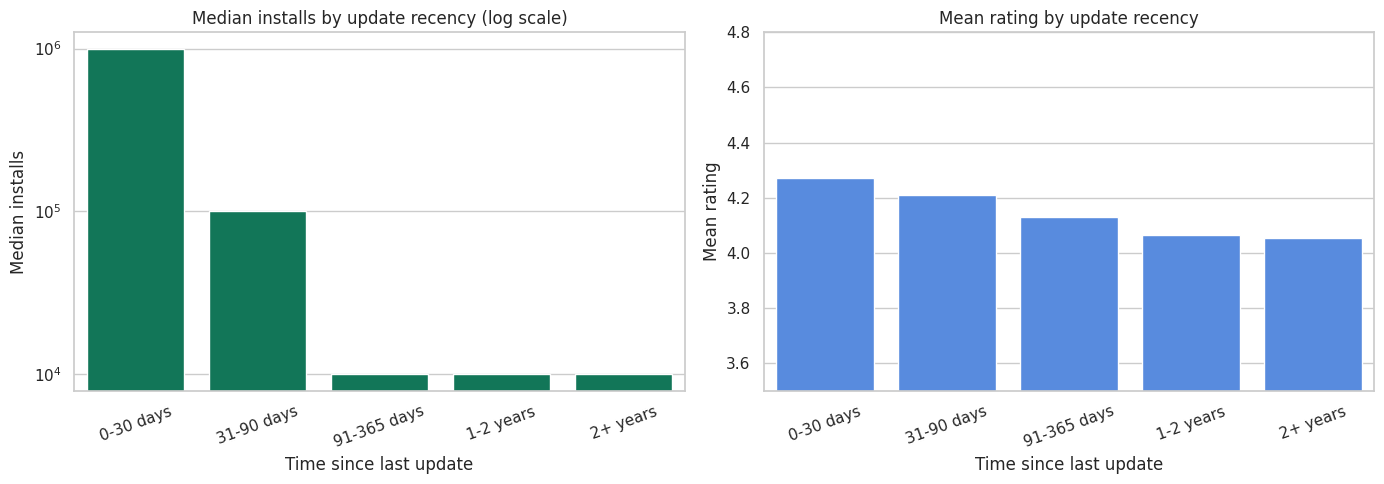


### Answer to RQ6

- **Installs:** days since last update vs. installs Spearman rho = **-0.33** (weak; negative means fresher apps have more installs). Vs. reviews: -0.34.
- **Ratings:** days since update vs. rating rho = **-0.18** (negligible).
- **Maintenance gap between tiers:** 78% of apps with 1M+ installs were updated within 180 days of the snapshot, versus 55% for 10K-1M and 49% for <10K.
- **Reading:** frequent updates go with greater reach, but the direction of cause is unclear: successful apps can afford to update often, and updates can drive installs.


In [31]:
rec = clean_df.dropna(subset=["days_since_update"])
rho_ri = stats.spearmanr(rec["days_since_update"], rec["installs"])
rr = rec.dropna(subset=["rating"])
rho_rr = stats.spearmanr(rr["days_since_update"], rr["rating"])
rho_rv = stats.spearmanr(rec["days_since_update"], rec["reviews"])

rec_stats = (clean_df.groupby("recency_band", observed=True)
             .agg(apps=("app", "count"), median_installs=("installs", "median"),
                  median_rating=("rating", "median"), mean_rating=("rating", "mean"),
                  pct_1m_plus=("installs", lambda s: (s >= 1_000_000).mean() * 100))
             .reset_index())
display(rec_stats)

fresh = (clean_df.assign(fresh_180d=clean_df["days_since_update"] <= 180)
         .groupby("install_tier", observed=True)["fresh_180d"].mean().mul(100).rename("pct_updated_within_180d").reset_index())
display(fresh)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=rec_stats, x="recency_band", y="median_installs", color=GREEN, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Median installs by update recency (log scale)")
axes[0].set_xlabel("Time since last update"); axes[0].set_ylabel("Median installs"); axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=rec_stats, x="recency_band", y="mean_rating", color=BLUE, ax=axes[1])
axes[1].set_ylim(3.5, 4.8); axes[1].set_title("Mean rating by update recency")
axes[1].set_xlabel("Time since last update"); axes[1].set_ylabel("Mean rating"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/10_recency.png", dpi=150); plt.show()

fr = fresh.set_index("install_tier")["pct_updated_within_180d"]
ANSWERS["RQ6"] = (f"Days since update vs. installs rho = {rho_ri[0]:.2f} ({strength_label(rho_ri[0])}); vs. rating rho = {rho_rr[0]:.2f}; "
                  f"{fr.get('1M+', float('nan')):.0f}% of 1M+ apps were updated in the last 180 days vs. {fr.get('<10K', float('nan')):.0f}% of <10K apps.")

display(Markdown(f"""
### Answer to RQ6

- **Installs:** days since last update vs. installs Spearman rho = **{rho_ri[0]:.2f}** ({strength_label(rho_ri[0])}; negative means fresher apps have more installs). Vs. reviews: {rho_rv[0]:.2f}.
- **Ratings:** days since update vs. rating rho = **{rho_rr[0]:.2f}** ({strength_label(rho_rr[0])}).
- **Maintenance gap between tiers:** {fr.get('1M+', float('nan')):.0f}% of apps with 1M+ installs were updated within 180 days of the snapshot, versus {fr.get('10K-1M', float('nan')):.0f}% for 10K-1M and {fr.get('<10K', float('nan')):.0f}% for <10K.
- **Reading:** {'frequent updates go with greater reach' if rho_ri[0] < -0.2 else 'update recency is only weakly linked to reach'}, but the direction of cause is unclear: successful apps can afford to update often, and updates can drive installs.
"""))

---
## RQ7. Which content-rating groups and genres dominate, and which genres are crowded?

**H1:** the market is concentrated in a few genres and in the "Everyone" audience. **Method:** shares of apps and installs, the Herfindahl-Hirschman index (HHI) for genre concentration, and a **saturation index** (share of apps divided by share of installs; above 1 means more apps than the install pie would suggest).

,content_rating,apps,total_installs,median_installs,median_rating,pct_apps,pct_installs
0,Everyone,7903,52378941861,"50,000.000",4.300,81.820,69.540
1,Teen,1036,16487275393,"500,000.000",4.300,10.726,21.889
2,Mature 17+,393,2437986878,"500,000.000",4.200,4.069,3.237
3,Everyone 10+,322,4016271795,"1,000,000.000",4.300,3.334,5.332
4,Adults only 18+,3,2000000,"500,000.000",4.500,0.031,0.003
5,Unrated,2,50500,"25,250.000",4.100,0.021,0.000


,primary_genre,apps,total_installs,median_installs,median_rating,pct_apps,pct_installs,saturation_index
0,Tools,829,8102771915,"50,000.000",4.200,8.583,10.757,0.798
1,Entertainment,592,3160114684,"50,000.000",4.200,6.129,4.195,1.461
2,Education,580,452160708,"10,000.000",4.400,6.005,0.600,10.003
3,Business,420,697164865,"1,000.000",4.200,4.348,0.926,4.698
4,Medical,395,38293077,"1,000.000",4.300,4.089,0.051,80.440
5,Personalization,376,1532494782,"10,000.000",4.400,3.893,2.035,1.913
6,Productivity,374,5793091369,"100,000.000",4.300,3.872,7.691,0.503
7,Lifestyle,370,503923539,"10,000.000",4.200,3.831,0.669,5.726
8,Finance,345,455348734,"10,000.000",4.300,3.572,0.605,5.908
9,Sports,335,1423174498,"100,000.000",4.300,3.468,1.889,1.836


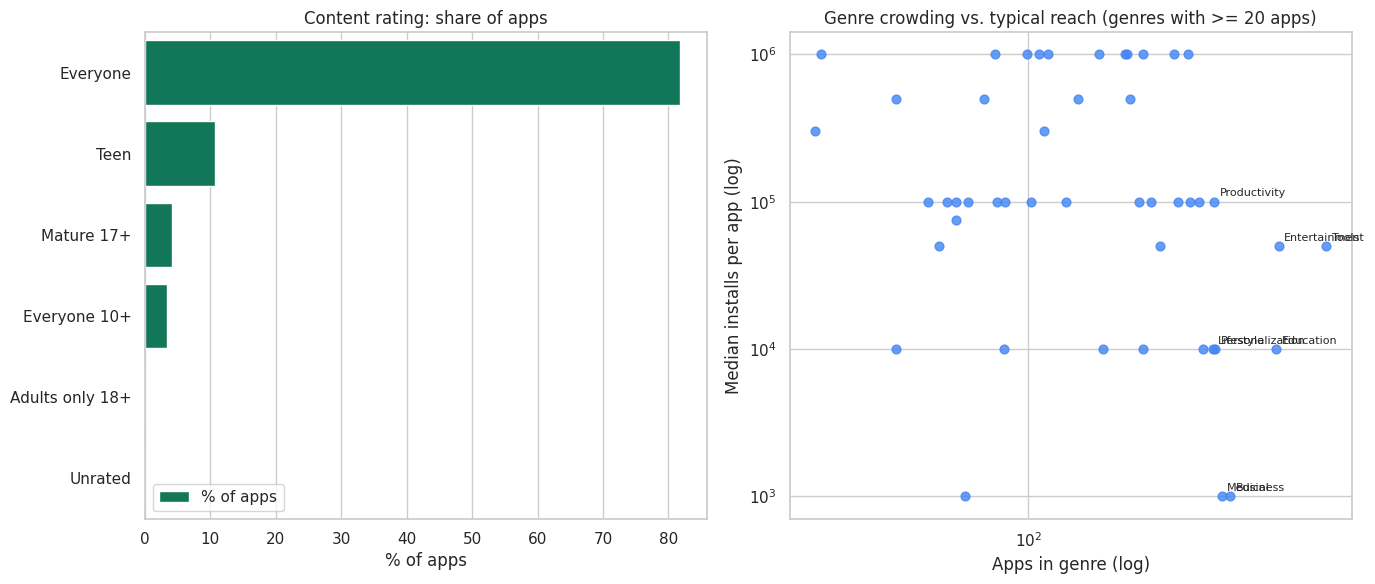


### Answer to RQ7

- **Audience:** `Everyone` apps are **82%** of listings and **70%** of installs; the next group is `Teen` (11% of apps).
- **Concentration:** the five biggest primary genres hold **29%** of apps. HHI = 0.036 across 48 genres (an even spread would be 0.021), so the market is fairly spread out across genres.
- **Crowding vs. reach:** across genres with >= 20 apps, number of apps vs. median installs per app has Spearman rho = -0.28 (crowded genres tend to offer lower reach per app). Crowded genres with the lowest typical reach: Business (420 apps, median 1,000 installs), Medical (395 apps, median 1,000 installs), Education (580 apps, median 10,000 installs).
- **Highest saturation index** (share of apps / share of installs, >= 20 apps): Medical (80.4), Events (31.2), Beauty (15.2); **lowest:** Communication (0.2), Video Players & Editors (0.3), Social (0.3).


In [32]:
# Content rating
cr = (clean_df.groupby("content_rating")
      .agg(apps=("app", "count"), total_installs=("installs", "sum"),
           median_installs=("installs", "median"), median_rating=("rating", "median"))
      .assign(pct_apps=lambda d: d["apps"] / d["apps"].sum() * 100,
              pct_installs=lambda d: d["total_installs"] / d["total_installs"].sum() * 100)
      .sort_values("apps", ascending=False).reset_index())
display(cr)

# Genre crowding (primary genre)
genre = (clean_df.groupby("primary_genre")
         .agg(apps=("app", "count"), total_installs=("installs", "sum"),
              median_installs=("installs", "median"), median_rating=("rating", "median"))
         .assign(pct_apps=lambda d: d["apps"] / d["apps"].sum() * 100,
                 pct_installs=lambda d: d["total_installs"] / d["total_installs"].sum() * 100)
         .assign(saturation_index=lambda d: d["pct_apps"] / d["pct_installs"])
         .sort_values("apps", ascending=False).reset_index())
genre_big = genre[genre["apps"] >= 20]
display(genre.head(12))

hhi_genre = hhi(genre["apps"]); hhi_even = 1 / len(genre)
top5_share = genre["pct_apps"].head(5).sum()
rho_gc = stats.spearmanr(genre_big["apps"], genre_big["median_installs"])
crowded = genre_big[(genre_big["pct_apps"] >= genre_big["pct_apps"].median())].nsmallest(3, "median_installs")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=cr, y="content_rating", x="pct_apps", color=GREEN, ax=axes[0], label="% of apps")
axes[0].set_title("Content rating: share of apps"); axes[0].set_xlabel("% of apps"); axes[0].set_ylabel("")
axes[1].scatter(genre_big["apps"], genre_big["median_installs"], s=40, color=BLUE, alpha=0.8)
for r in genre_big.nlargest(8, "apps").itertuples():
    axes[1].annotate(r.primary_genre, (r.apps, r.median_installs), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title(f"Genre crowding vs. typical reach (genres with >= 20 apps)")
axes[1].set_xlabel("Apps in genre (log)"); axes[1].set_ylabel("Median installs per app (log)")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/11_audience_and_genres.png", dpi=150); plt.show()

ANSWERS["RQ7"] = (f"'{cr.iloc[0]['content_rating']}' holds {cr.iloc[0]['pct_apps']:.0f}% of apps; top 5 genres hold {top5_share:.0f}% of apps "
                  f"(HHI {hhi_genre:.3f} vs. {hhi_even:.3f} if even); genre size vs. median installs rho = {rho_gc[0]:.2f}.")

display(Markdown(f"""
### Answer to RQ7

- **Audience:** `{cr.iloc[0]['content_rating']}` apps are **{cr.iloc[0]['pct_apps']:.0f}%** of listings and **{cr.iloc[0]['pct_installs']:.0f}%** of installs; the next group is `{cr.iloc[1]['content_rating']}` ({cr.iloc[1]['pct_apps']:.0f}% of apps).
- **Concentration:** the five biggest primary genres hold **{top5_share:.0f}%** of apps. HHI = {hhi_genre:.3f} across {len(genre)} genres (an even spread would be {hhi_even:.3f}), so the market is {'moderately concentrated' if hhi_genre > 2 * hhi_even else 'fairly spread out'} across genres.
- **Crowding vs. reach:** across genres with >= 20 apps, number of apps vs. median installs per app has Spearman rho = {rho_gc[0]:.2f} ({'crowded genres tend to offer lower reach per app' if rho_gc[0] <= -0.2 else 'crowded genres tend to offer higher reach per app' if rho_gc[0] >= 0.2 else 'no clear link between crowding and reach'}). Crowded genres with the lowest typical reach: {', '.join(f"{r.primary_genre} ({r.apps} apps, median {r.median_installs:,.0f} installs)" for r in crowded.itertuples())}.
- **Highest saturation index** (share of apps / share of installs, >= 20 apps): {', '.join(f"{r.primary_genre} ({r.saturation_index:.1f})" for r in genre_big.nlargest(3, 'saturation_index').itertuples())}; **lowest:** {', '.join(f"{r.primary_genre} ({r.saturation_index:.1f})" for r in genre_big.nsmallest(3, 'saturation_index').itertuples())}.
"""))

---
## RQ8. Which relationships survive when everything is considered together?

**H1:** installs remain the dominant correlate of reviews after controlling for category, rating, price, size, and recency. **Method:** OLS with category fixed effects on the complete-case sample; all numeric predictors are standardized so coefficients are comparable. We report how much R² each block adds, and a second model for what predicts **installs** without using reviews.

,model,R2,n
0,Reviews ~ category,0.117,7026
1,Reviews ~ category + installs,0.906,7026
2,Reviews ~ category + installs + attributes,0.922,7026
3,Reviews ~ category + attributes (no installs),0.229,7026
4,Installs ~ category,0.096,7026
5,Installs ~ category + attributes,0.206,7026


,reviews_model,installs_model
days since update,0.010,-0.086
installs (log),0.934,NaN
price (log),0.071,-0.170
size (log),0.046,0.242
rating,0.099,0.031


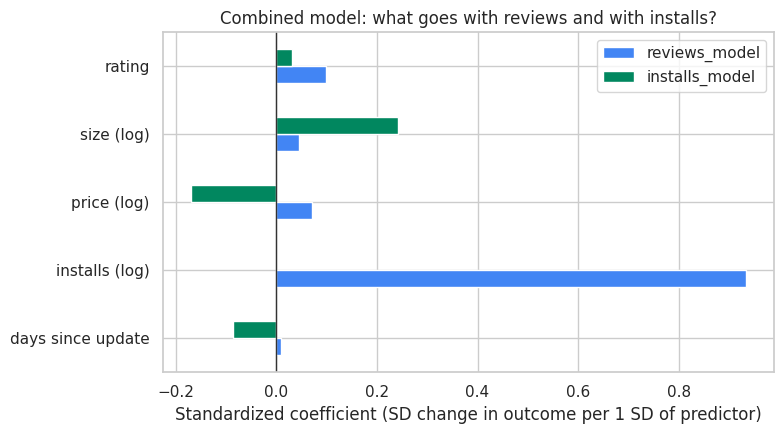


### Answer to RQ8

- **Installs dominate reviews:** category alone explains R² = 0.12 of log-reviews; adding installs raises it to **0.91** (+0.79). Adding rating, price, size, and recency adds only +0.02 more (final R² = 0.92). Standardized effect of installs: **0.93** SD per SD.
- **Without installs**, the other attributes plus category explain R² = 0.23 of log-reviews, which shows how much of their signal installs absorb.
- **What predicts installs (reviews excluded):** category alone R² = 0.10; with rating, price, size, and recency R² = **0.21**. The largest standardized coefficient is **size (log)** (0.24).
- **Read with care:** n = 7,026 apps with complete data (unrated and unsized apps are excluded), the install variable is bucketed, and this is a descriptive model, not a causal one.


In [33]:
model_df = clean_df.copy()
model_df["days_since_update_f"] = model_df["days_since_update"].astype(float)
model_df["is_paid_f"] = model_df["is_paid"].astype(float)

# Models for log10(reviews): category only -> + installs -> + all attributes (same complete-case sample)
sample_cols = ["log10_reviews", "log10_installs", "rating", "log10_price1", "log10_size_mb", "days_since_update_f", "is_paid_f", "category"]
cc = model_df[sample_cols].dropna()

attrs = ["rating", "log10_price1", "log10_size_mb", "days_since_update_f"]
m_cat   = ols_fit(cc, "log10_reviews", [], "category")
m_inst  = ols_fit(cc, "log10_reviews", ["log10_installs"], "category")
m_all   = ols_fit(cc, "log10_reviews", ["log10_installs"] + attrs, "category")
m_attr  = ols_fit(cc, "log10_reviews", attrs, "category")      # without installs

# What predicts installs (reviews deliberately excluded)?
m_inst_cat = ols_fit(cc, "log10_installs", [], "category")
m_inst_all = ols_fit(cc, "log10_installs", attrs, "category")

fit_table = pd.DataFrame({
    "model": ["Reviews ~ category", "Reviews ~ category + installs", "Reviews ~ category + installs + attributes",
              "Reviews ~ category + attributes (no installs)", "Installs ~ category", "Installs ~ category + attributes"],
    "R2": [m_cat["r2"], m_inst["r2"], m_all["r2"], m_attr["r2"], m_inst_cat["r2"], m_inst_all["r2"]],
    "n": [m_cat["n"]] * 4 + [m_inst_cat["n"]] * 2,
})
display(fit_table)

betas = pd.DataFrame({"reviews_model": m_all["coefs"], "installs_model": m_inst_all["coefs"]}).rename(
    index={"log10_installs": "installs (log)", "rating": "rating", "log10_price1": "price (log)",
           "log10_size_mb": "size (log)", "days_since_update_f": "days since update"})
display(betas)

fig, ax = plt.subplots(figsize=(8, 4.5))
betas.plot.barh(ax=ax, color=[BLUE, GREEN])
ax.axvline(0, color="#333", lw=1); ax.set_xlabel("Standardized coefficient (SD change in outcome per 1 SD of predictor)")
ax.set_title("Combined model: what goes with reviews and with installs?")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/12_combined_model.png", dpi=150); plt.show()

gain_inst = m_inst["r2"] - m_cat["r2"]
gain_attr = m_all["r2"] - m_inst["r2"]
strongest_attr_inst = betas["installs_model"].abs().idxmax()
ANSWERS["RQ8"] = (f"Adding installs lifts R² for reviews from {m_cat['r2']:.2f} to {m_inst['r2']:.2f} (+{gain_inst:.2f}); all other attributes add only "
                  f"+{gain_attr:.2f}. Attributes plus category explain {m_inst_all['r2']:.2f} of install variation (top: {strongest_attr_inst}).")

display(Markdown(f"""
### Answer to RQ8

- **Installs dominate reviews:** category alone explains R² = {m_cat['r2']:.2f} of log-reviews; adding installs raises it to **{m_inst['r2']:.2f}** (+{gain_inst:.2f}). Adding rating, price, size, and recency adds only +{gain_attr:.2f} more (final R² = {m_all['r2']:.2f}). Standardized effect of installs: **{betas.loc['installs (log)', 'reviews_model']:.2f}** SD per SD.
- **Without installs**, the other attributes plus category explain R² = {m_attr['r2']:.2f} of log-reviews, which shows how much of their signal installs absorb.
- **What predicts installs (reviews excluded):** category alone R² = {m_inst_cat['r2']:.2f}; with rating, price, size, and recency R² = **{m_inst_all['r2']:.2f}**. The largest standardized coefficient is **{strongest_attr_inst}** ({betas.loc[strongest_attr_inst, 'installs_model']:.2f}).
- **Read with care:** n = {m_all['n']:,} apps with complete data (unrated and unsized apps are excluded), the install variable is bucketed, and this is a descriptive model, not a causal one.
"""))

---
## Optional: Spark-side confirmation of the category ranking (window function)
To keep a distributed-processing angle on a research question, the category rating ranking is recomputed **in Spark** with `groupBy`, `percentile_approx`, and a `dense_rank` window. It should agree with the Pandas answer to RQ2 (names are uppercase here because Pandas title-cases them later).

In [34]:
try:
    cat_spark = (
        clean_sdf.filter(F.col("rating").isNotNull())
        .groupBy("category")
        .agg(F.count("*").alias("rated_apps"),
             F.round(F.avg("rating"), 3).alias("mean_rating"),
             F.expr("percentile_approx(rating, 0.5)").alias("median_rating_approx"))
        .filter(F.col("rated_apps") >= MIN_N)
        .withColumn("rank_by_mean_rating", F.dense_rank().over(Window.orderBy(F.desc("mean_rating"))))
        .orderBy("rank_by_mean_rating")
    )
    display(to_pandas_safe(cat_spark).head(10))
except Exception as exc:                                  # noqa: BLE001
    print(f"Spark confirmation skipped: {type(exc).__name__}: {exc}")

,category,rated_apps,mean_rating,median_rating_approx,rank_by_mean_rating
0,EVENTS,45,4.436,4.500,1
1,ART_AND_DESIGN,59,4.359,4.400,2
2,EDUCATION,106,4.355,4.400,3
3,BOOKS_AND_REFERENCE,169,4.345,4.500,4
4,PERSONALIZATION,298,4.332,4.400,5
5,PARENTING,50,4.300,4.400,6
6,BEAUTY,42,4.279,4.300,7
7,SOCIAL,203,4.247,4.300,8
8,GAME,899,4.245,4.300,9
9,HEALTH_AND_FITNESS,244,4.243,4.500,10


### Research scorecard
All answers below were generated by the code above. Evidence strength is judged from the effect size (not from p-values).

In [35]:
QUESTIONS = {
    "RQ1": "Do apps with more installs get more reviews?",
    "RQ2": "Which categories have the best ratings?",
    "RQ3": "Do paid apps earn higher ratings than free apps?",
    "RQ4": "How does app size relate to installs and ratings?",
    "RQ5": "How does price relate to installs?",
    "RQ6": "How do installs and ratings vary with update recency?",
    "RQ7": "Which content-rating groups and genres dominate or are crowded?",
    "RQ8": "Which relationships survive in a combined model?",
}
effect = {
    "RQ1": strength_label(rho_s),
    "RQ2": eps2_label(eps2),
    "RQ3": delta_label(d3_adj),
    "RQ4": strength_label(rho_si[0]),
    "RQ5": delta_label(d5),
    "RQ6": strength_label(rho_ri[0]),
    "RQ7": "descriptive",
    "RQ8": "large" if gain_inst > 0.25 else ("moderate" if gain_inst > 0.1 else "small"),
}
scorecard = pd.DataFrame({"RQ": list(QUESTIONS), "question": list(QUESTIONS.values()),
                          "effect size": [effect[k] for k in QUESTIONS], "answer (generated)": [ANSWERS[k] for k in QUESTIONS]})
with pd.option_context("display.max_colwidth", None):
    display(scorecard.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
scorecard.to_csv(os.path.join(os.path.dirname(CLEAN_PATH) or ".", "research_scorecard.csv"), index=False)

RQ,question,effect size,answer (generated)
RQ1,Do apps with more installs get more reviews?,very strong,Very strong positive relationship: Spearman rho = 0.97 (95% CI 0.97 to 0.97); each 10x more installs goes with about 8.2x more reviews (R² = 0.92); positive in 100% of categories.
RQ2,Which categories have the best ratings?,small,"Highest median ratings: Events, Books & Reference, Health & Fitness (4.5); lowest: Tools, Maps & Navigation, Dating (4.1). Category explains 2.5% of rating rank variance (small effect)."
RQ3,Do paid apps earn higher ratings than free apps?,negligible,Paid apps average +0.10 rating points vs. free (median diff +0.10); Cliff's delta 0.16 (small); after category adjustment 0.14 (negligible).
RQ4,How does app size relate to installs and ratings?,weak,Size vs. installs: Spearman rho = 0.31 (weak positive); 1M+ install share peaks in the 60+ MB band; size vs. rating rho = 0.05.
RQ5,How does price relate to installs?,large,"Free apps have a median of 100,000 installs vs. 1,000 for paid (Cliff's delta 0.50, large); among paid apps price vs. installs rho = 0.13."
RQ6,How do installs and ratings vary with update recency?,weak,Days since update vs. installs rho = -0.33 (weak); vs. rating rho = -0.18; 78% of 1M+ apps were updated in the last 180 days vs. 49% of <10K apps.
RQ7,Which content-rating groups and genres dominate or are crowded?,descriptive,'Everyone' holds 82% of apps; top 5 genres hold 29% of apps (HHI 0.036 vs. 0.021 if even); genre size vs. median installs rho = -0.28.
RQ8,Which relationships survive in a combined model?,large,Adding installs lifts R² for reviews from 0.12 to 0.91 (+0.79); all other attributes add only +0.02. Attributes plus category explain 0.21 of install variation (top: size (log)).


### Limitations that apply to the whole analysis
- **Association, not causation.** Reviews and installs, price and installs, and updates and installs can all influence each other in both directions.
- **Bucketed installs** hide true counts and produce many rank ties.
- **Selection in ratings.** Only apps with enough reviews have a rating, so rating questions (RQ2, RQ3, RQ6) describe that subset.
- **Snapshot scrape** with unknown sampling; apps may have changed since.
- **Many comparisons.** With about 10k apps, tiny differences are statistically significant, so effect sizes drive the conclusions, not p-values.
- **Primary genre only.** Apps with several genres are assigned their first one.

### Phase 6: Tableau Dashboard Design

**Data source:** `data/google_play_store_cleaned.csv` (exported above). Use `installs_bucket` sorted by `installs_bucket_rank`; `size_band`, `price_band`, `recency_band`, and `install_tier` are already ordered text fields.

**Core visualizations, each tied to a research question**

| # | Visualization | Question answered | Build notes |
|---|---|---|---|
| 1 | KPI tiles: apps, total installs, median rating, median reviews per 1,000 installs | Market snapshot | Median calculated fields |
| 2 | Scatter: `installs` vs `reviews` (log axes), colored by `type` | RQ1 | Log axes; trend line (Analytics pane) with R² |
| 3 | Box plot / bar: median reviews and review rate by `installs_bucket` | RQ1 | Sort by `installs_bucket_rank`; reference line at overall median |
| 4 | Bar with CI-style labels: median rating by `category` | RQ2 | Filter to categories with >= 30 rated apps; highlight top and bottom 3 |
| 5 | Free vs. paid: rating distribution and installs | RQ3, RQ5 | Side-by-side box plots; `price_band` bars |
| 6 | Size band and recency band bars (share with 1M+ installs, mean rating) | RQ4, RQ6 | Use the ordered band fields |
| 7 | Genre bubble chart: apps vs. median installs; content-rating bars | RQ7 | Size by total installs; label top genres |
| 8 | Outlier table: top apps by review rate | RQ1 residuals | Filter installs >= 1,000 |

**Suggested multi-page structure**
1. **Overview:** KPIs plus the headline scatter (visualizations 1, 2).
2. **Reviews and Installs:** buckets, review rate, outlier table (3, 8).
3. **Ratings:** category ratings, free vs. paid (4, 5).
4. **App Traits:** size, price, recency (5, 6).
5. **Market Structure:** genres and audience (7).

**Interactivity:** filters for `category`, `type`, `content_rating`, `install_tier`; a **parameter** to switch the metric (reviews, rating, review rate) and a minimum-installs threshold; navigation buttons between pages; consistent colors (green = installs, blue = reviews, red = highlights) across every page. The charts saved in `./images/` are the prototypes for each Tableau view.

**Design documentation:** record here why each chart type was chosen, the palette, and any trade-offs after you build the dashboard.

### Link to Published Dashboard

**Tableau Public URL:** `PASTE_YOUR_TABLEAU_PUBLIC_LINK_HERE`

*(Replace the placeholder after publishing, and test the link in a private browser window.)*

In [36]:
# Executive summary assembled from the computed answers (so it can never disagree with the evidence)
display(Markdown("### Findings at a glance\n\n" + "\n".join(f"- **{k}. {QUESTIONS[k]}** {ANSWERS[k]}" for k in QUESTIONS)))

### Findings at a glance

- **RQ1. Do apps with more installs get more reviews?** Very strong positive relationship: Spearman rho = 0.97 (95% CI 0.97 to 0.97); each 10x more installs goes with about 8.2x more reviews (R² = 0.92); positive in 100% of categories.
- **RQ2. Which categories have the best ratings?** Highest median ratings: Events, Books & Reference, Health & Fitness (4.5); lowest: Tools, Maps & Navigation, Dating (4.1). Category explains 2.5% of rating rank variance (small effect).
- **RQ3. Do paid apps earn higher ratings than free apps?** Paid apps average +0.10 rating points vs. free (median diff +0.10); Cliff's delta 0.16 (small); after category adjustment 0.14 (negligible).
- **RQ4. How does app size relate to installs and ratings?** Size vs. installs: Spearman rho = 0.31 (weak positive); 1M+ install share peaks in the 60+ MB band; size vs. rating rho = 0.05.
- **RQ5. How does price relate to installs?** Free apps have a median of 100,000 installs vs. 1,000 for paid (Cliff's delta 0.50, large); among paid apps price vs. installs rho = 0.13.
- **RQ6. How do installs and ratings vary with update recency?** Days since update vs. installs rho = -0.33 (weak); vs. rating rho = -0.18; 78% of 1M+ apps were updated in the last 180 days vs. 49% of <10K apps.
- **RQ7. Which content-rating groups and genres dominate or are crowded?** 'Everyone' holds 82% of apps; top 5 genres hold 29% of apps (HHI 0.036 vs. 0.021 if even); genre size vs. median installs rho = -0.28.
- **RQ8. Which relationships survive in a combined model?** Adding installs lifts R² for reviews from 0.12 to 0.91 (+0.79); all other attributes add only +0.02. Attributes plus category explain 0.21 of install variation (top: size (log)).

In [37]:
# Data-driven recommendations: each line appears only when the computed evidence supports it
tier_rate = (clean_df[clean_df["installs"] >= 1_000].groupby("install_tier", observed=True)["reviews_per_1k_installs"].median())
recs = {"Developers": [], "Product managers": [], "Investors": []}

recs["Developers"].append("Benchmark your review rate against your install tier (median reviews per 1,000 installs): "
                          + ", ".join(f"{t}: {v:.1f}" for t, v in tier_rate.items()) + ". A rate far below this suggests an untapped review-prompt opportunity.")
if eps2 >= 0.01:
    recs["Developers"].append(f"Category matters for ratings ({eps2_label(eps2)} effect): best-rated categories are {', '.join(ct.head(3)['category'])}.")
else:
    recs["Developers"].append("Category explains almost none of the variation in ratings, so do not choose a category for its rating reputation alone.")
if len(crowded):
    recs["Developers"].append(f"Check crowding before entering a genre: {', '.join(crowded['primary_genre'])} are large genres with low typical reach per app.")

recs["Product managers"].append(
    {"clear": "Charging goes with clearly lower reach, so pair a paid model with a free tier or trial.",
     "mod": "Charging goes with modestly lower reach; test price points rather than assuming a large penalty.",
     "none": "Free and paid apps reach similar audiences in this data, so price type is not a strong reach lever."}
    ["clear" if d5 >= 0.33 else "mod" if d5 >= 0.147 else "none"])
if rho_ri[0] <= -0.2:
    recs["Product managers"].append("Fresher apps have more installs: keep a regular update cadence (direction of cause is uncertain).")
else:
    recs["Product managers"].append("Update recency has little rank relationship with reach here, so do not expect updates alone to drive installs.")
if abs(rho_si[0]) >= 0.2:
    recs["Product managers"].append(f"App size has a {strength_label(rho_si[0])} link with installs (rho = {rho_si[0]:.2f}); monitor it, but treat it as a proxy for complexity.")
recs["Product managers"].append("Track the review rate (reviews per install), not just review counts, to separate reach from engagement.")

recs["Investors"].append(f"Review counts are a {strength_label(rho_s)} popularity screen (rho = {rho_s:.2f}), but installs are bucketed and the link is correlational, so confirm with other data.")
if m_all["r2"] - m_inst["r2"] < 0.02:
    recs["Investors"].append("Once installs are known, rating, price, size, and recency add almost nothing to explaining reviews.")

display(Markdown("### Data-driven recommendations\n\n" + "\n\n".join(
    f"**{who}**\n" + "\n".join(f"- {line}" for line in lines) for who, lines in recs.items())))

### Data-driven recommendations

**Developers**
- Benchmark your review rate against your install tier (median reviews per 1,000 installs): <10K: 14.0, 10K-1M: 14.1, 1M+: 20.7. A rate far below this suggests an untapped review-prompt opportunity.
- Category matters for ratings (small effect): best-rated categories are Events, Books & Reference, Health & Fitness.
- Check crowding before entering a genre: Business, Medical, Education are large genres with low typical reach per app.

**Product managers**
- Charging goes with clearly lower reach, so pair a paid model with a free tier or trial.
- Fresher apps have more installs: keep a regular update cadence (direction of cause is uncertain).
- App size has a weak link with installs (rho = 0.31); monitor it, but treat it as a proxy for complexity.
- Track the review rate (reviews per install), not just review counts, to separate reach from engagement.

**Investors**
- Review counts are a very strong popularity screen (rho = 0.97), but installs are bucketed and the link is correlational, so confirm with other data.
- Once installs are known, rating, price, size, and recency add almost nothing to explaining reviews.

## Conclusion

**Answer to the primary question (RQ1).** The scorecard and the "Answer to RQ1" cell report the measured strength of the installs-reviews relationship, with rank correlation, a bootstrap CI, the log-log slope, and robustness checks. Copy those generated numbers into the BLUF at the top so the summary and the evidence match.

**What the extended research adds (RQ2 to RQ8)**
- **Ratings (RQ2, RQ3):** category differences and the free vs. paid gap are reported as effect sizes with uncertainty, after checking that unrated apps are a different (less popular) group.
- **App traits (RQ4 to RQ6):** size, price, and update recency are compared with installs and ratings using rank methods, bands, and category-adjusted checks.
- **Market structure (RQ7):** audience groups and genres are compared on share of apps vs. share of installs, which shows where the market is crowded.
- **Combined view (RQ8):** a category-controlled regression shows how much of reviews and installs the measured traits explain together.

**Recommendations.** The cell above (*Data-driven recommendations*) generates each recommendation from the computed effect sizes, so a recommendation only appears when the data supports it.

**Limitations and future work**
- Correlation is not causation, and the data cannot separate "popular apps attract reviews" from "reviews attract installs".
- Bucketed installs, a single snapshot, rating selection, and unknown app age limit precision.
- Future work: add app age or monthly review velocity, model review counts with a count regression (negative binomial) including category effects, add review text analysis, and repeat the analysis on a newer dataset.

**Technical recap**
- PySpark: configured session (Arrow off, so no `pyarrow`), explicit schema handling, `cache()`, native regex/`when` expressions instead of a Python UDF (with an optional UDF cross-check), two window functions (`row_number`, `percent_rank`) plus a `dense_rank` confirmation, `approxQuantile`, `percentile_approx`, native Spark correlation, and error handling around loading and cleaning.
- Pandas/SciPy: date parsing, feature engineering, validation, export, non-parametric tests, bootstrap CIs, effect sizes, and an OLS model written with NumPy.
- Output: a validated CSV for Tableau, `research_scorecard.csv`, and chart images in `./images/`.

## Appendix: AI Usage Log

The assignment requires recording prompts, AI responses, and modifications. Keep this table up to date and paste your **exact** prompts.

| # | Prompt used (paste exact text) | AI response (summary) | What I changed or verified |
|---|---|---|---|
| 1 | Asked what the task requires; asked for the deliverables and a step-by-step workflow | Summary of deliverables (notebook, cleaned CSV, Tableau link), grading criteria, and a 12-step plan | `[describe]` |
| 2 | Asked for a detailed README for GitHub (portfolio audience) | Portfolio-style README with placeholders for results | `[describe]` |
| 3 | Asked for the completed notebook with the main question: relationship between install volume and number of reviews | Full CRISP-DM notebook: PySpark loading and cleaning, validation, correlation and regression analysis, Tableau plan | Ran all cells. The cleaning cell failed with `ModuleNotFoundError: No module named 'pyarrow'` (Spark 4.x Python UDF worker). |
| 4 | "the dataset is 4mb pyarrow is causing a lot of errors also enhance the code and enhance the research questions and address the questions and answer them" | Removed the Python UDF and every Arrow dependency: size parsing is now a native Spark expression (`regexp_extract` + `when`), Arrow disabled in Spark config, `toPandas()` replaced by a `collect()`-based converter, `import pyarrow` removed. Expanded one question into eight (RQ1 to RQ8) with hypotheses, tests, effect sizes, charts, and auto-generated answers; added helper unit tests, richer validation, and a research scorecard. | `[describe what you ran, what you verified in the outputs, and anything you changed or rejected]` |
| 5 | `[add further prompts]` | `[...]` | `[...]` |